In [81]:
from pathlib import Path
import re, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import trapezoid
from scipy.optimize import least_squares, curve_fit, minimize_scalar

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})

# ---- chart style -------------------------------------------------------------------------------
# Validated colour-blind-safe palette (checked with a CVD/contrast validator). Colour always has the same
# meaning: blue = step DOWN, orange = step UP. Status colours are only used for pass/fail judgements.
from cycler import cycler
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
DIR_COL = {"down": PAL[0], "up": PAL[1]}
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
SURFACE, INK, INK2, MUTED, GRID, AXIS, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#f0efec"
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]   # sequential ramp
DOWN_SHADES = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]   # step-downs, light -> dark
UP_SHADES = ["#f5b38f", "#f08c5c", "#eb6834", "#bf4f22", "#8f3612"]     # step-ups, light -> dark

def shades(direction, n):
    """n colours of one direction's hue, light to dark (hue = direction, lightness = which step)."""
    ramp = DOWN_SHADES if direction == "down" else UP_SHADES
    idx = np.linspace(0, len(ramp) - 1, n).round().astype(int) if n > 1 else [2]
    return [ramp[i] for i in idx]
DIVERGING = ["#2a78d6", "#f0efec", "#e34948"]                                          # blue <-> grey <-> red
WIN_T, WIN_S = "#eda100", "#1baf7a"   # background tint of the transient and stable windows
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=PAL), "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "grid.color": GRID, "grid.linewidth": 0.6, "grid.alpha": 1.0, "grid.linestyle": "-",
    "lines.linewidth": 1.6, "lines.markersize": 5, "legend.frameon": False, "legend.fontsize": 8,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.titlelocation": "left", "font.family": "sans-serif"})

def shade_windows(ax, t0=0.05, label=True):
    """Tint the fixed transient (W_T) and stable (W_S) windows on a log-time axis."""
    ax.axvspan(t0, TRANSIENT_END, color=WIN_T, alpha=0.12, lw=0)
    ax.axvspan(STABLE_START, 70, color=WIN_S, alpha=0.12, lw=0)
    if label:
        ax.text(np.sqrt(t0 * TRANSIENT_END), 0.98, "transient window", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=7, color=INK2)
        ax.text(np.sqrt(STABLE_START * 63), 0.98, "stable window", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=7, color=INK2)


def find_dir(candidates, marker):
    """First folder among `candidates` that contains `marker`, so the notebook runs from either location."""
    for c in candidates:
        p = Path(c)
        if p.is_dir() and any(p.glob(marker)):
            return p
    raise FileNotFoundError(f"none of {candidates} contains {marker}")

# ---- paths -------------------------------------------------------------------------
DATA_DIR = find_dir([".", "../New folder", "New folder", ".."], "JUN18.xlsx")                       # folder holding the client .xlsx workbooks
OUT = Path("step_analysis_outputs"); OUT.mkdir(exist_ok=True)
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)

# Workbooks with no raw step time series (see measurement inventory)
EXCLUDE_WORKBOOKS = ("AY21", "AUG18")
# Sheets that contain step-like tests but are out of scope for step-up/down
EXCLUDE_SHEETS = ("bureau",)               # FEB18 'Bureau Step Up & Stop' = start-up from rest

# ---- step verification ---------------------------------------------------------------
RATE_TOL = 0.05            # measured initial/final rate must be within 5 % of the protocol label
RATE_SETTLE_TOL = 0.05     # rate is 'settled' once it stays within 5 % of the target (or 0.01 1/s)
MIN_INSTRUMENT_WINDOW = 0.05   # s; never analyse stress earlier than this after the step (motor inertia)

# ---- fixed transient / stable rule -----------------------------------------------------
# Justification: the structural time constant of blood is tau_lambda ~ 1.1 s (Frontiers 2022, 12 donors).
#   transient window  W_T = [instrument settle, 2 s]   (about 2 tau_lambda: structure still evolving)
#   stable window     W_S = [30 s, end of test]        (> 25 tau_lambda: structure should have equilibrated)
# The gap 2-30 s is 'late transient' and belongs to neither label.
TRANSIENT_END = 2.0
STABLE_START = 30.0
STABLE_MAX_DRIFT = 0.10    # W_S is a *defensible* stable state only if stress drifts < 10 % across it
SETTLE_BAND = 0.10         # settling time: stress stays within +-10 % of the stable value
NOISE_PA = 0.001           # Pa; absolute noise floor (checked empirically in section 4)

# Sensitivity analysis boundaries for section 7.4
RULE_VARIANTS = {"primary (2 s / 30 s)": (2.0, 30.0), "short (1 s / 20 s)": (1.0, 20.0),
                 "long (5 s / 40 s)": (5.0, 40.0)}

# ---- relaxation model -------------------------------------------------------------------
D_EXP = 0.5                # shear-aggregation exponent, fixed at 1/2 in all four papers
TAU_LAMBDA_LIT = (1.13, 0.24)   # s, mean and SD over 12 donors (Frontiers in Physics 2022, Table 6)
G_LIT_V1 = 0.29            # Pa, G of ethixo-EVP version 1, Donor 3 (Armstrong et al. 2021, Table 3) -- same model
G_LIT_R = (0.15, 0.05)     # Pa, rouleaux modulus G_R of the tensorial t-ESSTV, 12 donors (Frontiers 2022) -- related model
MODEL_MAX_NRMSE = 0.10     # a step is 'poorly fitted' if RMS error > 10 % of that step's maximum stress

## 1. Load the step-up/down blocks

Every workbook uses the ARES-G2 export layout: row 1 holds the test label (e.g. `5-->2.5 (1/s)`), row 2 the variable names (`Step time`, `Stress`, `Strain`, `Shear rate`, …) and row 3 the units, with one block of columns per test. The reader below is **non-destructive**: it never edits the workbook and keeps the workbook, sheet and block number for every row, so each measurement can be traced back to its source.

APR18 has its header one row lower than the other files; the reader detects this automatically.

In [82]:
def storage_hours(sheet_title):
    """Storage time of the sample in hours, parsed from the sheet name ('t0', 't12', '24hr'); 0 if absent."""
    s = sheet_title.lower()
    m = re.search(r"\bt\s?(\d+)\b", s) or re.search(r"(\d+)\s?h", s)
    return float(m.group(1)) if m else 0.0

def parse_step_label(label):
    m = re.search(r"([\d.]+)\s*-->\s*([\d.]+)", label.replace(" ", ""))
    return (float(m.group(1)), float(m.group(2))) if m else (np.nan, np.nan)

def read_step_blocks(path):
    import openpyxl
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    out = []
    for ws in wb.worksheets:
        title = ws.title.strip()
        if "step" not in title.lower() or any(k in title.lower() for k in EXCLUDE_SHEETS):
            continue
        R = list(ws.iter_rows(values_only=True))
        if len(R) < 4:
            continue
        W = max(len(r) for r in R[:4])
        cell = lambda r, j: R[r][j] if j < len(R[r]) else None
        hr = 1 if any(str(v).strip().lower().startswith("step time") for v in R[1] if v) else 2
        hdr = [str(cell(hr, j)).strip().lower() if cell(hr, j) is not None else "" for j in range(W)]
        data = R[hr + 2:]
        tcols = [j for j, h in enumerate(hdr) if h.startswith("step time")]
        for k, c in enumerate(tcols):
            nxt = tcols[k + 1] if k + 1 < len(tcols) else W
            label = next((str(cell(0, j)).strip() for j in range(c, nxt) if cell(0, j) not in (None, "")), "")
            cols = {}
            for j in range(c, nxt):
                h = hdr[j]
                key = ("time" if h.startswith("step time") else "stress" if "stress" in h else
                       "shear_rate" if "shear rate" in h else "strain" if h.startswith("strain") else
                       "viscosity" if "viscosity" in h else None)
                if key and key not in cols:
                    cols[key] = np.array([r[j] if j < len(r) and isinstance(r[j], (int, float)) else np.nan
                                          for r in data], float)
            if "stress" not in cols:
                continue
            df = pd.DataFrame(cols)
            df = df[np.isfinite(df.time) & (df.time > 0) & np.isfinite(df.stress)].reset_index(drop=True)
            if len(df) < 10:
                continue
            g0, g1 = parse_step_label(label)
            out.append(dict(workbook=path.name, sheet=title, block=k + 1, label=label,
                            storage_h=storage_hours(title), rate_from=g0, rate_to=g1, data=df))
    return out

blocks = []
for p in sorted(DATA_DIR.glob("*.xlsx")):
    if any(k in p.name for k in EXCLUDE_WORKBOOKS):
        continue
    blocks += read_step_blocks(p)

# Remove blocks whose whole stress trace repeats an earlier block (copy-pasted inside the workbooks; in one case,
# DEC17 24 h '.1-->1', only the stress column was copied and the shear-rate column differs)
seen = {}
for b in blocks:
    h = hashlib.md5(np.round(b["data"].stress.values, 9).tobytes()).hexdigest()
    b["duplicate_of"] = seen.get(h, "")
    seen.setdefault(h, f'{b["workbook"]}::{b["sheet"]}::{b["label"]}')
dups = [(b["workbook"], b["sheet"], b["label"], b["duplicate_of"]) for b in blocks if b["duplicate_of"]]
print(f"{len(dups)} blocks removed as stress-trace duplicates:")
for d_ in dups:
    print("  ", d_[0][:14], "|", d_[1], "|", d_[2], "  ==  ", d_[3].split("::", 1)[1])
blocks = [b for b in blocks if not b["duplicate_of"]]

for i, b in enumerate(blocks):
    b["step_id"] = f"S{i+1:03d}"
    m = re.search(r"(\d{1,2}[A-Z]{3}\d{0,2}|[A-Z]{3}\d{2})", b["workbook"])       # e.g. JUN18, 12FEB20, DEC17
    b["sample"] = m.group(1) if m else b["workbook"]
    b["n_points"] = len(b["data"])
    b["high_res"] = b["n_points"] > 1000

inv = pd.DataFrame([{k: v for k, v in b.items() if k != "data"} for b in blocks])
print(f"{len(inv)} step blocks from {inv.workbook.nunique()} workbooks "
      f"({inv.high_res.sum()} high-resolution, {(~inv.high_res).sum()} log-spaced)")
inv.groupby("sample").agg(blocks=("step_id", "size"), storage_times=("storage_h", "nunique"))

7 blocks removed as stress-trace duplicates:
   14DEC_UDEL_Blo | Step UpDown | 0.1-->10   ==   Step UpDown::0.1-->5
   14DEC_UDEL_Blo | Step UpDown | 0.1-->20   ==   Step UpDown::0.1-->5
   9MAY19 UDEL Bl | Steps | 5-->.1(1/s)   ==   Steps::300-->5
   APR18 SS SAOS  | steps | 5-->.5   ==   steps::5-->0.1
   APR18 SS SAOS  | steps | .1-->.25   ==   steps::5-->0.1
   NOV18 UDEL ARE | Steps | .1-->10   ==   Steps::.1-->5
   UDEL Blood DEC | Step up Down 24hr | .1-->1 (1/s)   ==   Step up Down 24hr::.1-->.5(1/s)
136 step blocks from 11 workbooks (6 high-resolution, 130 log-spaced)


,blocks,storage_times
sample,,
12FEB20,10,1
14DEC,5,1
14MAR19,10,1
27FEB19,10,1
9MAY19,9,1
APR18,7,1
DEC17,41,3
FEB18,10,1
JUL18,14,1


### 1.2 Data map

**How to read this chart.** Rows are blood samples (a workbook, plus its storage time where the same blood was measured more than once); columns are step conditions written as *initial rate → final rate* in s⁻¹. A blue cell means that step-down was measured on that sample, an orange cell a step-up, a pale cell that it was not measured. **HR** marks the high-resolution recordings (about 4,200 points instead of 65).

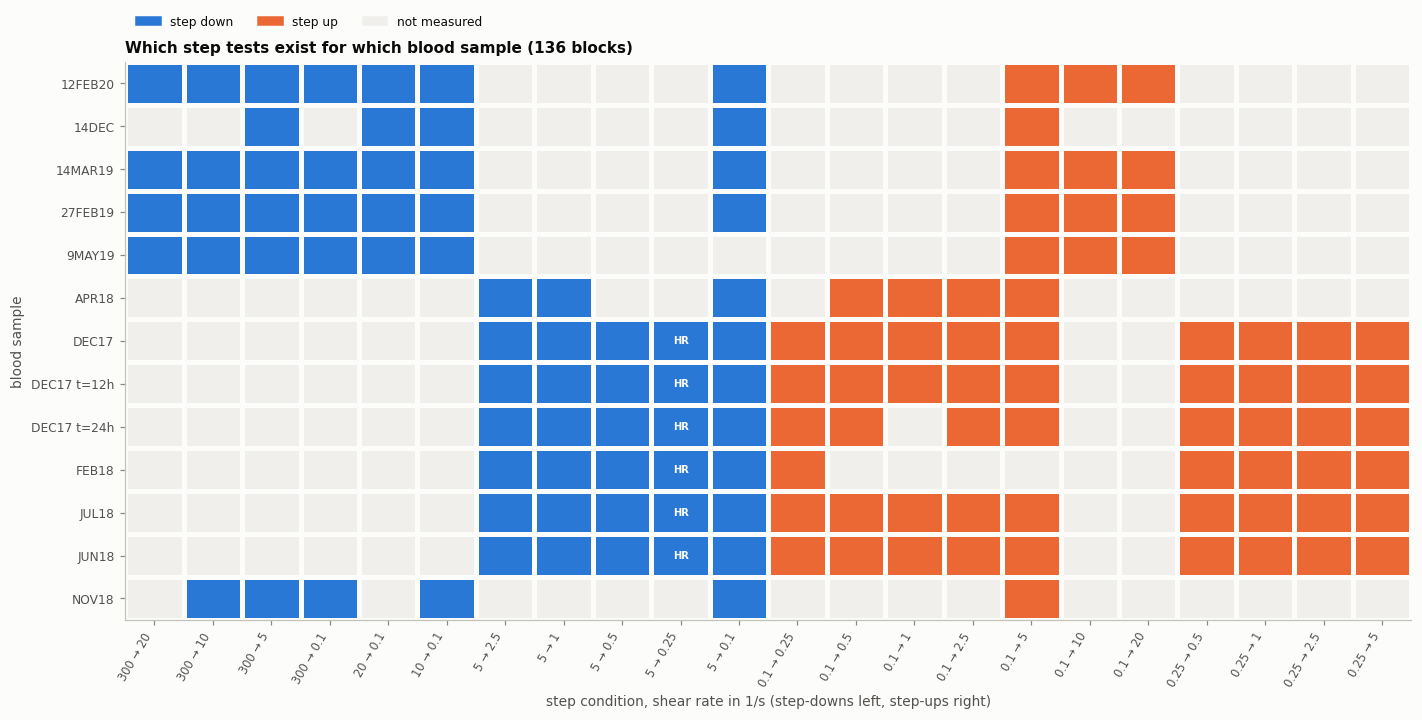

In [83]:
def unit_name(df):
    return df["sample"] + np.where(df.storage_h > 0, " t=" + df.storage_h.astype(int).astype(str) + "h", "")

def cond_name(df):
    return df.rate_from.map("{:g}".format) + " → " + df.rate_to.map("{:g}".format)

_c = inv.assign(cond=cond_name(inv), unit=unit_name(inv), up=inv.rate_to > inv.rate_from)
COND_ORDER = (_c[~_c.up].drop_duplicates("cond").sort_values(["rate_from", "rate_to"], ascending=False).cond.tolist() +
              _c[_c.up].drop_duplicates("cond").sort_values(["rate_from", "rate_to"]).cond.tolist())
UNIT_ORDER = _c.drop_duplicates("unit").sort_values(["sample", "storage_h"]).unit.tolist()
M = np.zeros((len(UNIT_ORDER), len(COND_ORDER)))
for _, r in _c.iterrows():
    M[UNIT_ORDER.index(r.unit), COND_ORDER.index(r.cond)] = 2 if r.up else 1

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(13, 0.34 * len(UNIT_ORDER) + 2.2))
ax.pcolormesh(M, cmap=ListedColormap([NEUTRAL, DIR_COL["down"], DIR_COL["up"]]), vmin=0, vmax=2,
              edgecolors=SURFACE, linewidth=2)
for _, r in _c[_c.high_res].iterrows():
    ax.text(COND_ORDER.index(r.cond) + 0.5, UNIT_ORDER.index(r.unit) + 0.5, "HR", ha="center", va="center",
            fontsize=6.5, color="white", fontweight="bold")
ax.set_xticks(np.arange(len(COND_ORDER)) + 0.5, COND_ORDER, rotation=60, ha="right", fontsize=7.5)
ax.set_yticks(np.arange(len(UNIT_ORDER)) + 0.5, UNIT_ORDER, fontsize=8)
ax.invert_yaxis(); ax.grid(False)
ax.set(xlabel="step condition, shear rate in 1/s (step-downs left, step-ups right)", ylabel="blood sample")
ax.set_title(f"Which step tests exist for which blood sample ({len(inv)} blocks)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=DIR_COL["down"], label="step down"), Patch(color=DIR_COL["up"], label="step up"),
                   Patch(color=NEUTRAL, label="not measured")], ncol=3, loc="lower left", bbox_to_anchor=(0, 1.04))
fig.tight_layout(); fig.savefig(FIG / "00_data_map.png", dpi=200); plt.show()

**What it shows.** The step tests come in two protocol groups. Six workbooks (12FEB20, 14MAR19, 27FEB19, 9MAY19, NOV18, 14DEC) mostly use large step-downs from 300, 20 or 10 s⁻¹ plus step-ups from 0.1 s⁻¹. The other five (DEC17, FEB18, JUL18, JUN18, APR18) use the 5 s⁻¹ ↔ 0.1/0.25 s⁻¹ family from the papers. Because each blood sample was tested with only one protocol group, step size is partly tied to the sample; this is why magnitude is tested *within* families (same sample, same starting rate) in §7.1. Matched reverse pairs exist only where both *a → b* and *b → a* are coloured, for example 5 → 0.1 with 0.1 → 5. All six high-resolution (HR) recordings are 5 → 0.25 s⁻¹ steps. (AUG18 appears only in the version that reads Member 1's dataset.)

### 1.1 Steady-state flow curves

Each workbook also has a steady-state flow curve (16 shear rates from 0.1 to 700 s⁻¹). The papers fit the steady-state parameters to this curve first, then fit the transient parameter to the steps. The flow curve is also used here as an independent check of the pre-step baseline and of the final plateau. Where a workbook has several flow curves (DEC17 at 0/12/24 h, FEB18 at 0/6/24 h), the one matching the step sheet's storage time is used.

In [84]:
def read_flow_curves(path):
    import openpyxl
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    curves = []
    for ws in wb.worksheets:
        if not re.search(r"\bSS\b|steady", ws.title, re.I):
            continue
        R = list(ws.iter_rows(values_only=True))
        for r_i in range(3):
            for j, v in enumerate(R[r_i]):
                if v is None or "shear rate" not in str(v).lower():
                    continue
                above = " ".join(str(R[k][j]) for k in range(r_i) if j < len(R[k]) and R[k][j])
                xs, ys = [], []
                for r in R[r_i + 1:]:
                    x = r[j] if j < len(r) else None; y = r[j + 1] if j + 1 < len(r) else None
                    if not isinstance(x, (int, float)) or not isinstance(y, (int, float)) or (xs and x <= xs[-1]):
                        break
                    xs.append(x); ys.append(y)
                if len(xs) >= 8:
                    m = re.search(r"(\d+)", above)
                    curves.append(dict(storage_h=float(m.group(1)) if m else 0.0,
                                       rate=np.array(xs), stress=np.array(ys)))
    return curves

flow = {p.name: read_flow_curves(p) for p in sorted(DATA_DIR.glob("*.xlsx"))
        if not any(k in p.name for k in EXCLUDE_WORKBOOKS)}

def flow_curve_for(workbook, storage_h):
    cs = flow.get(workbook, [])
    match = [c for c in cs if c["storage_h"] == storage_h]
    return (match or cs or [None])[0]

def flow_stress(fc, rate):
    """Log-log interpolation of the flow-curve stress at a given shear rate."""
    if fc is None or not np.isfinite(rate) or rate <= 0:
        return np.nan
    return float(np.exp(np.interp(np.log(rate), np.log(fc["rate"]), np.log(np.clip(fc["stress"], 1e-6, None)))))

print({k: [c["storage_h"] for c in v] for k, v in flow.items()})

{'12FEB20 UDEL Blood.xlsx': [0.0], '14DEC_UDEL_Blood_Rheo.xlsx': [0.0], '14MAR19 SS SAOS STEP LAOS etc.xlsx': [0.0], '27FEB19 UDEL Blood.xlsx': [0.0], '9MAY19 UDEL Blood.xlsx': [0.0], 'APR18 SS SAOS STEPS LAOS UDLAOS.xlsx': [0.0], 'FEB18 UDEL ARES G2 SS LAOS SAW STEP UP DATA.xlsx': [0.0, 6.0, 24.0], 'JUL18.xlsx': [0.0], 'JUN18.xlsx': [0.0, 0.0], 'NOV18 UDEL ARESG2 DATA.xlsx': [0.0], 'UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELTON.xlsx': [0.0, 12.0, 24.0]}


## 2. What a step block looks like

Before building features, look at the raw signal. Two things matter for everything that follows:

1. **The first few milliseconds are still at the starting rate.** The motor changes speed about 5–20 ms into the block, so the first 3–6 points give a genuine pre-step baseline.
2. **The shear rate rings.** The rate briefly overshoots the target (for example it reaches −0.16 s⁻¹ on a 5 → 0.1 step) before settling at about 0.05 s. Stress in that window reflects motor inertia, not the blood (the same instrument-inertia issue discussed by Das et al. 2024, cited in the Semester 1 report), so it is excluded from all features.

**How to read this chart.** Both panels share the same horizontal axis: time since the start of the recorded block, on a logarithmic scale so that the first milliseconds and the last minute are both visible. The grey band is the instrument window that is excluded from every feature. Left: the applied shear rate, with the target rate as a horizontal line. Right: the stress the blood produces in response.

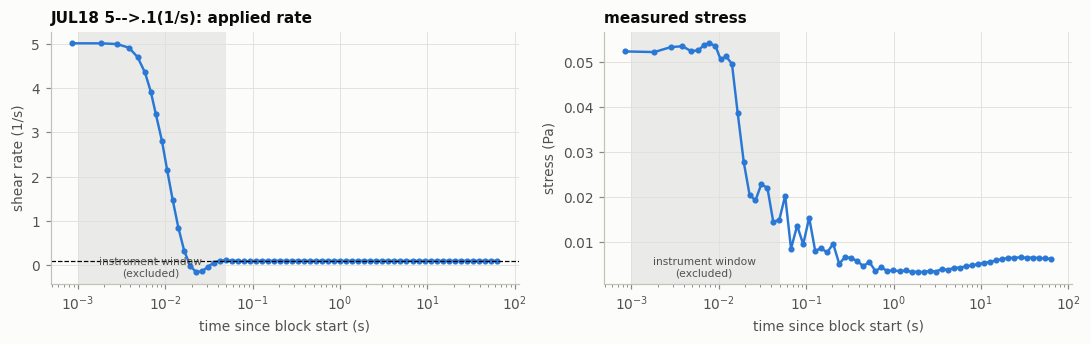

In [85]:
ex = next(b for b in blocks if b["sample"] == "JUL18" and b["label"].startswith("5-->.1"))
d = ex["data"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].semilogx(d.time, d.shear_rate, "o-", ms=3); ax[0].axhline(ex["rate_to"], color="k", lw=0.8, ls="--")
ax[0].set(xlabel="time since block start (s)", ylabel="shear rate (1/s)", title=f'{ex["sample"]} {ex["label"]}: applied rate')
ax[1].semilogx(d.time, d.stress, "o-", ms=3, color=PAL[0])
ax[1].set(xlabel="time since block start (s)", ylabel="stress (Pa)", title="measured stress")
for a in ax:
    a.axvspan(1e-3, MIN_INSTRUMENT_WINDOW, color=MUTED, alpha=0.15, lw=0)
    a.text(0.0068, 0.03, "instrument window\n(excluded)", transform=a.get_xaxis_transform(), ha="center", fontsize=7, color=INK2)
fig.tight_layout(); fig.savefig(FIG / "01_raw_step_block.png", dpi=200); plt.show()

## 3. Verify every step event against the protocol

For each block:

* **Measured initial rate** = median shear rate of the points before the motor starts to move.
* **Step time** t_step = first time the rate has moved more than half-way from the initial to the final value.
* **Measured final rate** = median shear rate for t ≥ 1 s.
* **Rate settling time** = time after which the rate stays within 5 % of the target (the end of the instrument window).
* **Rate overshoot** = largest excursion of the rate beyond the target, as a fraction of the step size.
* **Magnitude** is reported as the rate ratio r = final/initial and as log₁₀ r; **direction** is `up` if r > 1.

A block passes if both measured rates are within 5 % of its label. High-resolution blocks start after the step, so their initial rate cannot be measured and is taken from the label (flagged).

In [86]:
def verify_step(b):
    d = b["data"]; t = d.time.values
    g0_lab, g1_lab = b["rate_from"], b["rate_to"]
    res = dict(step_id=b["step_id"])
    if "shear_rate" not in d or d.shear_rate.isna().all():
        # no rate channel: time is zeroed at the step, so t_step = 0 and the instrument window is the minimum
        res.update(rate_from_meas=np.nan, rate_to_meas=np.nan, has_pre_step=False, t_step=0.0,
                   t_rate_settle=MIN_INSTRUMENT_WINDOW, rate_overshoot_frac=np.nan,
                   qc_rate="label only (no shear-rate channel)")
        return res
    g = d.shear_rate.values
    g1 = np.nanmedian(g[t >= 1.0])
    has_pre = t[0] < 0.004 and abs(g[0] - g1) > 0.3 * abs(g1_lab - g0_lab)
    g0 = np.nanmedian(g[:3]) if has_pre else g0_lab
    half = g0 + 0.5 * (g1 - g0)
    moved = np.where(np.sign(g1 - g0) * (g - half) > 0)[0]
    t_step = t[moved[0]] if has_pre and len(moved) else 0.005     # median observed value when not measurable
    tol = np.maximum(RATE_SETTLE_TOL * abs(g1), 0.01)
    bad = np.where(np.abs(g - g1) > tol)[0]
    t_rs = t[bad[-1] + 1] if len(bad) and bad[-1] + 1 < len(t) else t[0]
    after = g[t > t_step]
    excess = (np.max(after) - g1) if g1 > g0 else (g1 - np.min(after))
    ok0 = has_pre and abs(g0 / g0_lab - 1) <= RATE_TOL
    ok1 = abs(g1 / g1_lab - 1) <= RATE_TOL
    res.update(rate_from_meas=g0, rate_to_meas=g1, has_pre_step=has_pre, t_step=t_step,
               t_rate_settle=max(t_rs, MIN_INSTRUMENT_WINDOW), rate_overshoot_frac=excess / abs(g1 - g0),
               qc_rate=("ok" if ok0 and ok1 else
                        "final ok, initial from label (no pre-step samples)" if ok1 and not has_pre else
                        "MISMATCH with label"))
    return res

ev = inv.merge(pd.DataFrame([verify_step(b) for b in blocks]), on="step_id")
ev["ratio"] = ev.rate_to / ev.rate_from
ev["log10_ratio"] = np.log10(ev.ratio)
ev["direction"] = np.where(ev.ratio > 1, "up", "down")
ev["magnitude_abs"] = (ev.rate_to - ev.rate_from).abs()

print(ev.qc_rate.value_counts().to_string())
cols = ["step_id", "sample", "sheet", "label", "storage_h", "rate_from", "rate_to", "rate_from_meas", "rate_to_meas",
        "direction", "log10_ratio", "t_step", "t_rate_settle", "rate_overshoot_frac", "qc_rate"]
ev[cols].to_csv(OUT / "step_events.csv", index=False)
ev[cols].head(12)

qc_rate
ok                                                    127
final ok, initial from label (no pre-step samples)      6
MISMATCH with label                                     3


,step_id,sample,sheet,label,storage_h,rate_from,rate_to,rate_from_meas,rate_to_meas,direction,log10_ratio,t_step,t_rate_settle,rate_overshoot_frac,qc_rate
0,S001,12FEB20,Steps,10-->.1,0.0,10.0,0.1,9.986000,0.100012,down,-2.000000,0.010504,0.057501,0.052045,ok
1,S002,12FEB20,Steps,300--> 20(1/s),0.0,300.0,20.0,300.026000,20.002400,down,-1.176091,0.014173,0.050000,0.036953,ok
2,S003,12FEB20,Steps,300-->5,0.0,300.0,5.0,300.020000,5.000600,down,-1.778151,0.014161,0.067170,0.036195,ok
3,S004,12FEB20,Steps,300-->10,0.0,300.0,10.0,300.023000,10.001200,down,-1.477121,0.014167,0.050000,0.036517,ok
4,S005,12FEB20,Steps,5-->.1(1/s),0.0,5.0,0.1,5.027830,0.100012,down,-1.698970,0.010497,0.092498,0.052133,ok
5,S006,12FEB20,Steps,20-->.1,0.0,20.0,0.1,19.957000,0.100012,down,-2.301030,0.010479,0.057476,0.052000,ok
6,S007,12FEB20,Steps,300-->.1,0.0,300.0,0.1,300.026000,0.100012,down,-3.477121,0.013355,0.103016,0.038982,ok
7,S008,12FEB20,Steps,.1-->5,0.0,0.1,5.0,0.101051,5.000605,up,1.698970,0.010661,0.050000,0.050673,ok
8,S009,12FEB20,Steps,.1-->10,0.0,0.1,10.0,0.102100,10.001200,up,2.000000,0.010492,0.050000,0.050560,ok
9,S010,12FEB20,Steps,.1-->20,0.0,0.1,20.0,0.105109,20.002400,up,2.301030,0.010490,0.050000,0.053203,MISMATCH with label


In [87]:
bad = ev[ev.qc_rate.str.startswith("MISMATCH")]
print(f"{len(bad)} blocks disagree with their label:")
bad[cols]

3 blocks disagree with their label:


,step_id,sample,sheet,label,storage_h,rate_from,rate_to,rate_from_meas,rate_to_meas,direction,log10_ratio,t_step,t_rate_settle,rate_overshoot_frac,qc_rate
9,S010,12FEB20,Steps,.1-->20,0.0,0.1,20.0,0.105109,20.002400,up,2.30103,0.010490,0.05,0.053203,MISMATCH with label
23,S024,14MAR19,Steps,.1-->10,0.0,0.1,10.0,-0.301885,10.001200,up,2.00000,0.014169,0.05,0.040367,MISMATCH with label
44,S045,APR18,steps,5-->0.1,0.0,5.0,0.1,5.005830,0.500059,down,-1.69897,0.010505,0.05,0.051908,MISMATCH with label


**Result.** 133 of 136 blocks match their protocol label. The three mismatches are kept out of all later sections:
* **APR18 `5-->0.1`**: the measured final rate is 0.50 s⁻¹, so this block is really a 5 → 0.5 step. It looks like a labelling error in the workbook and should be reported to the client.
* **14MAR19 `.1-->10`**: the rate before the step is −0.30 s⁻¹, not 0.1, so the sample was not at the stated starting state (the workbook also contains a flow-reversal test, which may have preceded it; this cannot be confirmed from the file).
* **12FEB20 `.1-->20`**: the initial rate is 0.105 s⁻¹, 5.1 % off, only just outside the tolerance. It is excluded for consistency with the fixed rule.

**Instrument window.** The table below summarises how long the motor takes to settle. Stress before `t_rate_settle` is excluded in every later section.

In [88]:
ev.groupby("direction")[["t_step", "t_rate_settle", "rate_overshoot_frac"]].describe(percentiles=[.5]).round(3)

t_step                                    t_rate_settle                                  rate_overshoot_frac                                   
           count   mean    std    min    50%    max         count   mean    std   min   50%    max               count   mean    std    min    50%    max
direction                                                                                                                                                
down        69.0  0.011  0.002  0.005  0.011  0.014          69.0  0.068  0.022  0.05  0.05  0.108                69.0  0.046  0.008  0.035  0.051  0.053
up          67.0  0.011  0.000  0.010  0.010  0.014          67.0  0.055  0.017  0.05  0.05  0.108                67.0  0.052  0.003  0.040  0.052  0.061

**How to read this chart.** Left and middle: every step test, placing the rate written in its label (horizontal) against the rate the rheometer actually applied (vertical), on log scales. Points on the grey diagonal match their label; red crosses fail the 5 % check and are named. A measured rate that was negative is drawn at the bottom edge. Right: how many milliseconds the motor took to settle at the new rate; everything before that is excluded from the analysis, and never less than 50 ms.

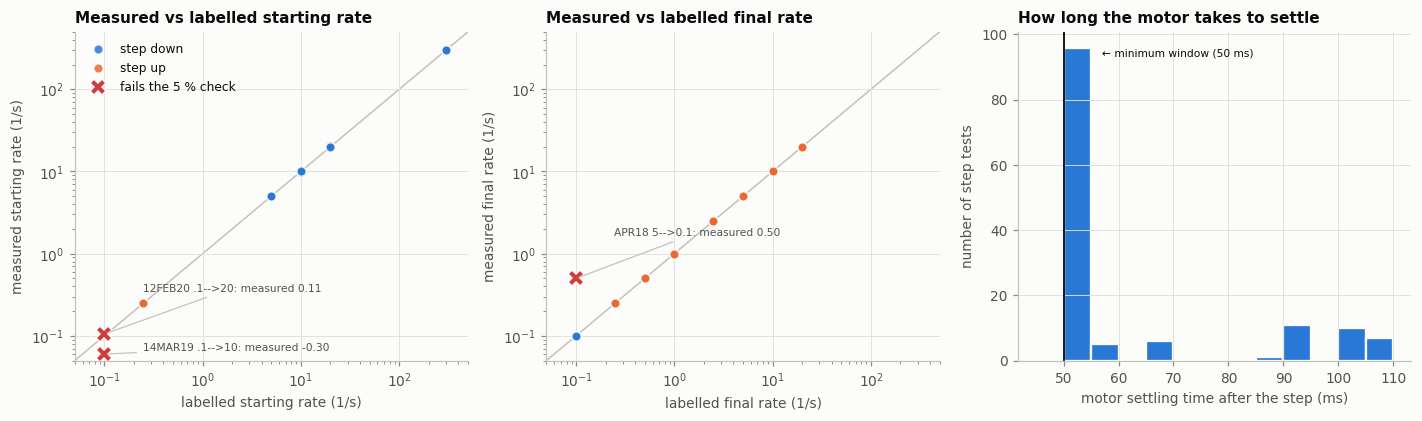

In [89]:
V = ev.copy()
ok = V.qc_rate != "MISMATCH with label"
fig, ax = plt.subplots(1, 3, figsize=(13, 3.9))
for a, lab, meas, ttl in [(ax[0], "rate_from", "rate_from_meas", "starting rate"), (ax[1], "rate_to", "rate_to_meas", "final rate")]:
    shown = lambda s_: s_.where(s_ > 0, 0.06)          # a negative measured rate is drawn at the bottom edge
    has = V[meas].notna()
    fail = has & ((V[meas] / V[lab] - 1).abs() > RATE_TOL)
    for dirn in ("down", "up"):
        q = V[has & ~fail & (V.direction == dirn)]
        a.loglog(q[lab], shown(q[meas]), "o", ms=6, color=DIR_COL[dirn], mec=SURFACE, mew=0.8, alpha=0.85, label=f"step {dirn}")
    bad = V[fail]
    a.loglog(bad[lab], shown(bad[meas]), "X", ms=11, color=STATUS["critical"], mec=SURFACE, label="fails the 5 % check")
    for k_, (_, r) in enumerate(bad.iterrows()):
        a.annotate(f'{r["sample"]} {r.label.split("(")[0].strip()}: measured {r[meas]:.2f}', (r[lab], shown(pd.Series([r[meas]])).iloc[0]),
                   textcoords="offset points", xytext=(25, 28 - 26 * k_), fontsize=7, color=INK2,
                   arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.8))
    lim = [0.05, 500]; a.plot(lim, lim, color=AXIS, lw=1, zorder=0)
    a.set(xlim=lim, ylim=lim, xlabel=f"labelled {ttl} (1/s)", ylabel=f"measured {ttl} (1/s)", title=f"Measured vs labelled {ttl}")
ax[0].legend(loc="upper left")
ax[2].hist(V.t_rate_settle * 1000, bins=np.arange(45, 115, 5), color=PAL[0], edgecolor=SURFACE, linewidth=1.5)
ax[2].axvline(MIN_INSTRUMENT_WINDOW * 1000, color=INK, lw=1.2)
ax[2].text(MIN_INSTRUMENT_WINDOW * 1000 + 7, 0.95, "← minimum window (50 ms)", transform=ax[2].get_xaxis_transform(), va="top", fontsize=7)
ax[2].set(xlabel="motor settling time after the step (ms)", ylabel="number of step tests", title="How long the motor takes to settle")
fig.tight_layout(); fig.savefig(FIG / "01b_step_verification.png", dpi=200); plt.show()

**What it shows.** Almost every point sits on the diagonal: the rheometer applied the rates written in the labels. Three blocks fail. Two step-ups start at the wrong rate (12FEB20 `.1-->20` is 5 % high; 14MAR19 `.1-->10` starts at −0.30 s⁻¹), and APR18 `5-->0.1` actually ends at 0.5 s⁻¹. The motor reaches the new rate within 50–55 ms in most tests and within about 110 ms in all of them, so excluding at least the first 50 ms removes the motor transient everywhere.

## 4. Fixed transient / stable rule

Defined in the configuration cell and justified by the literature time scale τ_λ ≈ 1.1 s:

* **Transient window W_T** = [rate settling time, 2 s]
* **Stable window W_S** = [30 s, end of test (≈ 63 s)]
* **Stable value** σ_stable = median stress in W_S
* **Defensible stable state**: the stress drift across W_S (from a linear fit of σ against log t) is less than 10 % of σ_stable (or less than the noise floor). Measurements that fail this **never reach a defensible stable state** and are flagged, not dropped.

The rule depends only on time, not on the stress feature being tested, so §7.3 is not circular.

### 4.1 Noise floor check
Before applying the rule, check that the fixed absolute noise floor (1 mPa) is realistic, using the scatter of stress about a smooth trend inside W_S.

In [90]:
def window(d, t0, t1):
    return d[(d.time >= t0) & (d.time <= t1)]

noise = []
for b in blocks:
    w = window(b["data"], STABLE_START, np.inf)
    if len(w) >= 4:
        x = np.log10(w.time.values); y = w.stress.values
        resid = y - np.polyval(np.polyfit(x, y, 1), x)
        noise.append(dict(step_id=b["step_id"], high_res=b["high_res"], resid_sd=np.std(resid, ddof=2),
                          stable_level=np.median(y)))
noise = pd.DataFrame(noise)
print(noise.groupby("high_res").resid_sd.describe(percentiles=[.5, .9]).round(5).to_string())
print(f"\nConfigured NOISE_PA = {NOISE_PA} Pa")

          count     mean      std      min      50%      90%      max
high_res                                                             
False     125.0  0.00056  0.00199  0.00001  0.00010  0.00106  0.02045
True        6.0  0.00387  0.00084  0.00271  0.00381  0.00479  0.00482

Configured NOISE_PA = 0.001 Pa


The log-spaced (65-point) blocks are much smoother than the high-resolution ones because the instrument averages over each logarithmic interval. The high-resolution 5 → 0.25 s⁻¹ blocks are dominated by noise at this low stress (≈ 0.01 Pa). **This matters for the Haemograph feature set:** at low shear rates, raw fast sampling needs averaging before transient features are stable.

To keep all measurements comparable (the framework's *same windows, same preprocessing* rule), high-resolution blocks are **averaged into the same logarithmic time bins** as the 65-point blocks before any feature is computed. The raw high-resolution series stays available to Member 4.

In [91]:
ref_grid = next(b for b in blocks if not b["high_res"])["data"].time.values
edges = np.sqrt(ref_grid[1:] * ref_grid[:-1]); edges = np.r_[ref_grid[0] / 1.2, edges, ref_grid[-1] * 1.2]

def log_bin(d):
    idx = np.digitize(d.time.values, edges) - 1
    g = d.assign(bin=idx).groupby("bin").mean(numeric_only=True)
    return g[g.index.isin(range(len(ref_grid)))].reset_index(drop=True)

for b in blocks:
    b["an"] = log_bin(b["data"]) if b["high_res"] else b["data"]   # 'analysis' series
print("high-res blocks after binning:", [len(b["an"]) for b in blocks if b["high_res"]])

high-res blocks after binning: [47, 47, 47, 47, 47, 47]


In [92]:
def windows_for(b, e, t_trans_end=TRANSIENT_END, t_stable_start=STABLE_START):
    d = b["an"]
    wt = window(d, e.t_rate_settle, t_trans_end)
    ws = window(d, t_stable_start, np.inf)
    s_stable = np.median(ws.stress) if len(ws) else np.nan
    if len(ws) >= 3:
        x = np.log10(ws.time.values)
        slope = np.polyfit(x, ws.stress.values, 1)[0]
        drift = slope * (x[-1] - x[0])
    else:
        drift = np.nan
    drift_frac = abs(drift) / max(abs(s_stable), NOISE_PA) if np.isfinite(drift) else np.nan
    return dict(n_transient=len(wt), n_stable=len(ws), sigma_stable=s_stable, stable_drift_Pa=drift,
                stable_drift_frac=drift_frac,
                stable_ok=bool(np.isfinite(drift_frac) and (drift_frac <= STABLE_MAX_DRIFT or abs(drift) <= NOISE_PA)),
                below_noise=bool(abs(s_stable) < 3 * NOISE_PA))

evi = ev.set_index("step_id")
win = pd.DataFrame([dict(step_id=b["step_id"], **windows_for(b, evi.loc[b["step_id"]])) for b in blocks])
ev = ev.drop(columns=[c for c in win.columns if c != "step_id" and c in ev], errors="ignore").merge(win, on="step_id")
ev[["step_id", "sample", "label", "n_transient", "n_stable", "sigma_stable", "stable_drift_frac",
    "stable_ok", "below_noise"]].to_csv(OUT / "step_windows.csv", index=False)

print(f"Defensible stable state reached: {ev.stable_ok.sum()} / {len(ev)} measurements")
print(f"Stable stress within 3x noise floor: {ev.below_noise.sum()}")
ev.assign(final_rate=ev.rate_to).groupby(["direction", "final_rate"]).stable_ok.agg(["mean", "size"]).round(2).T

Defensible stable state reached: 118 / 136 measurements
Stable stress within 3x noise floor: 0


direction    down                                              up                                      
final_rate  0.10  0.25  0.50  1.00  2.50  5.00  10.00 20.00 0.25  0.50   1.00   2.50  5.00  10.00 20.00
mean         0.57   1.0  0.83   1.0   1.0  0.83   1.0   1.0  0.83   1.0   0.91   0.92   1.0  0.75   1.0
size        28.00   6.0  6.00   7.0   7.0  6.00   5.0   4.0  6.00  12.0  11.00  12.00  18.0  4.00   4.0

**Result.** 118 of 136 measurements (87 %) reach a defensible stable state. The table shows **which step conditions fail to settle within 63 s**: only 57 % of steps down to 0.1 s⁻¹ settle, against 83–100 % for every other final rate. Steps *down* to low shear rates (0.1–0.25 s⁻¹) are the usual failures: stress is still rising at the end of the test, which is consistent with continuing rouleaux aggregation (Pincot et al. 2023: aggregation is much slower than breakdown). Their “final” value is therefore a lower bound, and features that divide by it are marked as less reliable in §8.

**How to read this chart.** Left: for each final shear rate, the share of step tests whose stress stops drifting (less than 10 % change across the stable window); step-downs in blue, step-ups in orange, with the count above each bar. Right: one step-down that does *not* settle, showing why: the black line is the trend fitted inside the stable window, and it is still rising at the end of the test.

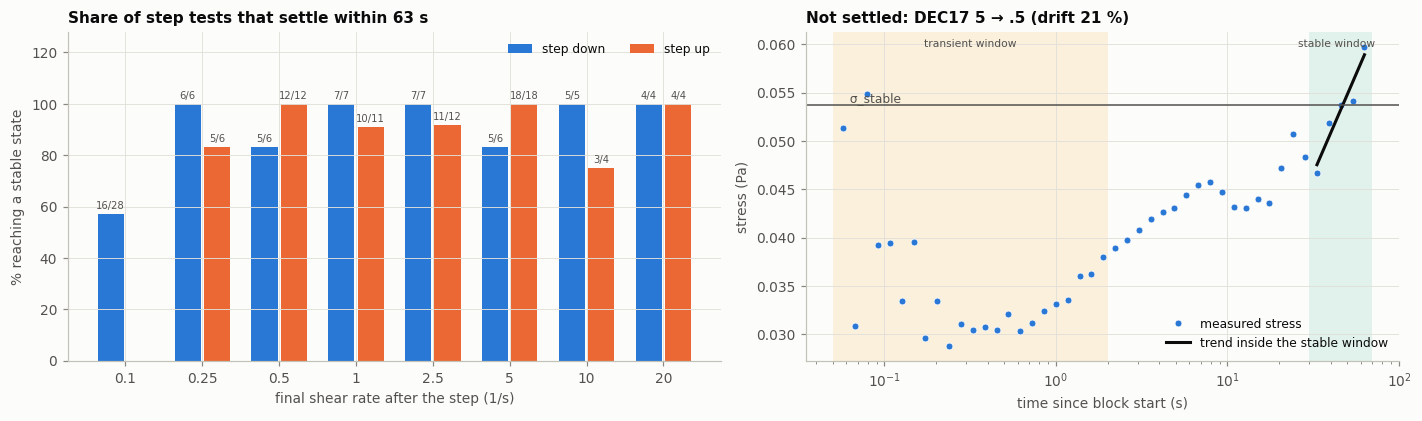

In [93]:
S_ = ev.groupby(["direction", "rate_to"]).stable_ok.agg(["sum", "size"]).reset_index()
rates = sorted(S_.rate_to.unique())
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw=dict(width_ratios=[1.1, 1]))
w = 0.38
for j, dirn in enumerate(["down", "up"]):
    q = S_[S_.direction == dirn].set_index("rate_to").reindex(rates)
    x = np.arange(len(rates)) + (j - 0.5) * w
    pct = 100 * q["sum"] / q["size"]
    ax[0].bar(x, pct, width=w - 0.04, color=DIR_COL[dirn], label=f"step {dirn}")
    for xi, p_, k, n in zip(x, pct, q["sum"], q["size"]):
        if np.isfinite(p_):
            ax[0].text(xi, p_ + 2, f"{int(k)}/{int(n)}", ha="center", fontsize=6.5, color=INK2)
ax[0].set_xticks(np.arange(len(rates)), [f"{r:g}" for r in rates])
ax[0].set(ylim=(0, 128), xlabel="final shear rate after the step (1/s)", ylabel="% reaching a stable state",
          title="Share of step tests that settle within 63 s")
ax[0].legend(loc="upper right", ncol=2)

fails_ = ev[~ev.stable_ok & (ev.direction == "down") & (ev.qc_rate != "MISMATCH with label")].sort_values("stable_drift_frac")
pick = fails_[fails_["sample"].isin(["JUL18", "JUN18", "DEC17"])]
pick = (pick if len(pick) else fails_).iloc[len((pick if len(pick) else fails_)) // 2]   # a typical, not the worst, failure
ex = next(b for b in blocks if b["step_id"] == pick.step_id)
e = ev.set_index("step_id").loc[ex["step_id"]]
d = ex["an"]; m = d.time >= e.t_rate_settle
ax[1].semilogx(d.time[m], d.stress[m], "o", ms=4.5, color=DIR_COL["down"], mec=SURFACE, mew=0.5, label="measured stress")
ws = window(d, STABLE_START, np.inf); xw = np.log10(ws.time.values)
coef = np.polyfit(xw, ws.stress.values, 1)
ax[1].plot(ws.time, np.polyval(coef, xw), color=INK, lw=2, label="trend inside the stable window")
ax[1].axhline(e.sigma_stable, color=INK2, lw=1)
ax[1].text(0.06, e.sigma_stable, " σ_stable", va="bottom", fontsize=8, color=INK2)
shade_windows(ax[1], e.t_rate_settle)
ax[1].set(xlabel="time since block start (s)", ylabel="stress (Pa)",
          title=f'Not settled: {ex["sample"]} {ex["label"].split("(")[0].strip().replace("-->", " → ")} (drift {100 * e.stable_drift_frac:.0f} %)')
ax[1].legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "02b_stable_state.png", dpi=200); plt.show()

**What it shows.** For every final rate of 0.25 s⁻¹ or more, at least 75 % of tests (usually 100 %) reach a stable state. Steps *down* to 0.1 s⁻¹ settle in only 16 of 28 tests. The example on the right shows the typical failure: the stress dips, recovers, and is still changing inside the stable window, so its "stable" value is only an estimate of the true steady state. There is no orange bar at 0.1 s⁻¹ because no step-up ends there.

## 5. Conventional transient features

All features are computed on t ≥ rate settling time (instrument window excluded). σ_stable is the W_S median from §4.

| Feature | Definition | Units |
|---|---|---|
| `sigma_pre` | median stress before the step (pre-step baseline) | Pa |
| `sigma_pre_fc` | flow-curve stress at the initial rate (independent baseline check) | Pa |
| `sigma_imm` | first stress value after the instrument window (immediate response) | Pa |
| `sigma_peak`, `t_peak` | maximum stress after the window and its time (time to peak) | Pa, s |
| `sigma_min`, `t_min` | minimum stress after the window and its time | Pa, s |
| `overshoot` | (σ_peak − σ_stable)/σ_stable | – |
| `undershoot` | (σ_stable − σ_min)/σ_stable | – |
| `jump_signed` | (σ_imm − σ_stable)/σ_stable, **signed relaxation amplitude** | – |
| `relax_amp` | σ_imm − σ_stable | Pa |
| `init_slope` | slope of σ/σ_stable against log₁₀ t between the window and 1 s | per decade |
| `settling_time` | time after which σ stays within ±10 % of σ_stable (NaN if never) | s |
| `area_log` | ∫ (σ − σ_stable)/σ_stable d(ln t) from the window to the end: net excess (+) or deficit (−) of stress relative to steady state | – |
| `plateau_vs_fc` | σ_stable / flow-curve stress at the final rate (checks the plateau against steady-shear data) | – |
| `visc_ratio` | (σ_stable/γ̇₁)/(σ_pre/γ̇₀), apparent viscosity after/before | – |

In [94]:
def features(b, e):
    d = b["an"]; t = d.time.values; s = d.stress.values
    fc = flow_curve_for(b["workbook"], b["storage_h"])
    ss = e.sigma_stable
    m = t >= e.t_rate_settle
    tm, sm = t[m], s[m]
    pre = s[t < 0.5 * e.t_step] if e.has_pre_step else np.array([])
    f = dict(step_id=b["step_id"])
    f["sigma_pre"] = np.median(pre) if len(pre) else np.nan
    f["sigma_pre_fc"] = flow_stress(fc, e.rate_from)
    f["sigma_final_fc"] = flow_stress(fc, e.rate_to)
    f["sigma_imm"] = sm[0]
    i_pk, i_mn = np.argmax(sm), np.argmin(sm)
    f.update(sigma_peak=sm[i_pk], t_peak=tm[i_pk], sigma_min=sm[i_mn], t_min=tm[i_mn])
    denom = abs(ss) if abs(ss) > NOISE_PA else np.nan
    f["overshoot"] = (sm[i_pk] - ss) / denom
    f["undershoot"] = (ss - sm[i_mn]) / denom
    f["jump_signed"] = (sm[0] - ss) / denom
    f["relax_amp"] = sm[0] - ss
    early = (tm <= 1.0)
    f["init_slope"] = (np.polyfit(np.log10(tm[early]), sm[early] / denom, 1)[0]
                       if early.sum() >= 3 and np.isfinite(denom) else np.nan)
    outside = np.where(np.abs(sm - ss) > max(SETTLE_BAND * abs(ss), NOISE_PA))[0]
    if len(outside) == 0:
        f["settling_time"] = tm[0]
    elif outside[-1] + 1 < len(tm) and tm[outside[-1] + 1] < STABLE_START:
        f["settling_time"] = tm[outside[-1] + 1]
    else:
        f["settling_time"] = np.nan
    f["area_log"] = trapezoid((sm - ss) / denom, np.log(tm))
    f["plateau_vs_fc"] = ss / f["sigma_final_fc"]
    f["baseline_vs_fc"] = f["sigma_pre"] / f["sigma_pre_fc"]
    f["visc_ratio"] = ((ss / e.rate_to) / (f["sigma_pre"] / e.rate_from)
                       if len(pre) and abs(f["sigma_pre"]) >= 3 * NOISE_PA else np.nan)   # baseline must exceed noise
    return f

evs = ev.set_index("step_id")
feat = pd.DataFrame([features(b, evs.loc[b["step_id"]]) for b in blocks])
steps = ev.merge(feat, on="step_id")
FEATURES = ["jump_signed", "overshoot", "undershoot", "init_slope", "settling_time", "t_peak", "t_min",
            "area_log", "relax_amp", "visc_ratio"]
steps.to_csv(OUT / "step_features.csv", index=False)
steps[["step_id", "sample", "label", "direction", "sigma_pre", "sigma_imm", "sigma_stable"] + FEATURES].head(10).round(4)

,step_id,sample,label,direction,sigma_pre,sigma_imm,sigma_stable,jump_signed,overshoot,undershoot,init_slope,settling_time,t_peak,t_min,area_log,relax_amp,visc_ratio
0,S001,12FEB20,10-->.1,down,0.0753,-0.0001,0.0038,-1.0185,3.1282,1.0185,-1.4482,10.9058,0.0788,0.0575,-1.6468,-0.0039,5.0993
1,S002,12FEB20,300--> 20(1/s),down,1.1957,0.1179,0.1270,-0.0719,0.1538,0.1288,0.1948,3.0460,0.5280,0.0787,0.3790,-0.0091,1.5930
2,S003,12FEB20,300-->5,down,1.1682,0.0626,0.0532,0.1770,0.7168,0.3870,0.3299,NaN,45.7985,0.0787,0.3502,0.0094,2.7317
3,S004,12FEB20,300-->10,down,1.2008,0.0782,0.0759,0.0305,0.2750,0.2771,0.3144,20.6357,1.1707,0.0787,0.7800,0.0023,1.8955
4,S005,12FEB20,5-->.1(1/s),down,0.0474,0.0045,0.0042,0.0770,1.0279,0.6520,-1.2583,10.9058,0.1083,1.3735,-1.1801,0.0003,4.4142
5,S006,12FEB20,20-->.1,down,0.1279,0.0076,0.0040,0.8879,2.1480,1.1684,-1.6144,12.7908,0.0788,0.0925,-2.7370,0.0036,6.2981
6,S007,12FEB20,300-->.1,down,1.1575,0.0024,NaN,NaN,NaN,NaN,NaN,0.1030,0.1195,0.1030,NaN,NaN,NaN
7,S008,12FEB20,.1-->5,up,0.0087,0.0678,0.0463,0.4658,0.7185,0.0250,-0.0127,15.0013,0.2035,53.7155,2.1944,0.0216,0.1063
8,S009,12FEB20,.1-->10,up,-0.0008,0.1040,0.0753,0.3821,0.7546,0.0281,-0.3532,NaN,15.0012,63.0007,1.9765,0.0288,NaN
9,S010,12FEB20,.1-->20,up,0.0096,0.2123,0.1253,0.6951,0.6951,0.0083,-0.5800,0.8513,0.0575,33.2933,1.2348,0.0871,0.0654


### 5.0 What each feature measures

**How to read this chart.** Two real step tests from the same blood sample (JUN18), drawn on log–log axes: a step **up** from 0.25 to 5 s⁻¹ (left) and a step **down** from 5 to 0.1 s⁻¹ (right). Grey squares are the stress before the step; coloured points are the stress after it; the grey band is the excluded instrument window. Each label points at the value a feature is computed from. The green band is ±10 % around the stable value; the *settling time* is when the stress enters that band for good.

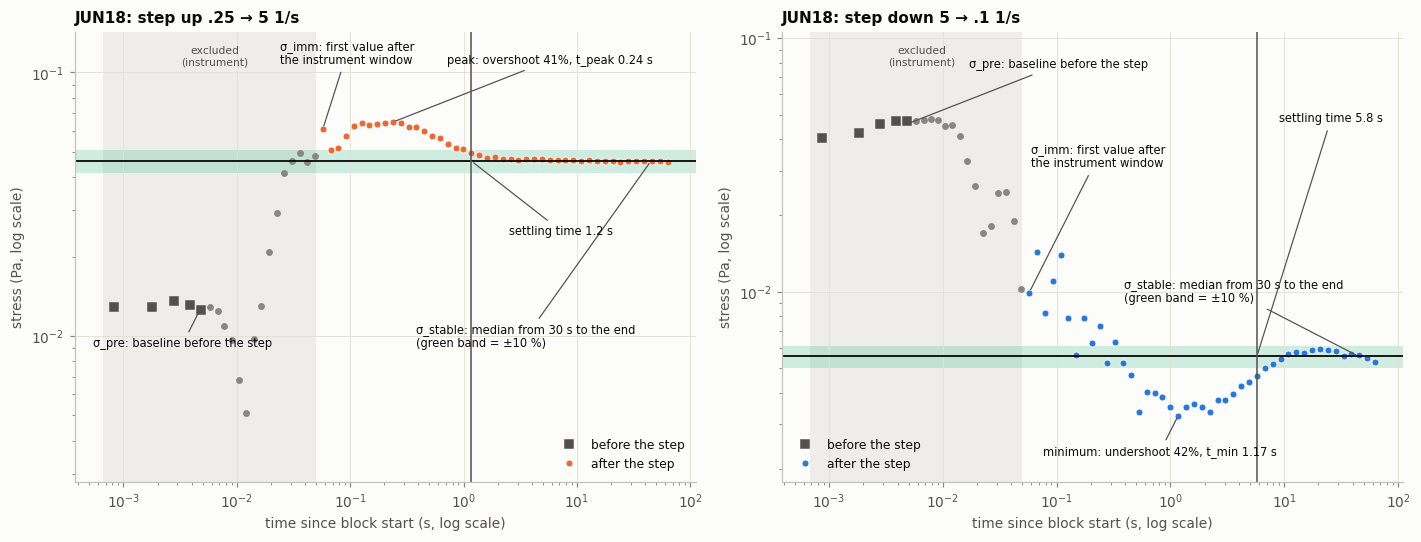

In [95]:
def anatomy(ax, sample, label_start, pos):
    b = next(bb for bb in blocks if bb["sample"] == sample and bb["label"].startswith(label_start))
    r = steps.set_index("step_id").loc[b["step_id"]]
    d = b["an"]; t = d.time.values; s = d.stress.values
    col = DIR_COL[r.direction]
    pre, post = t < 0.5 * r.t_step, t >= r.t_rate_settle
    ax.axvspan(t[0] * 0.8, r.t_rate_settle, color=MUTED, alpha=0.12, lw=0)
    ax.text(np.sqrt(t[0] * r.t_rate_settle), 0.97, "excluded\n(instrument)", transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=7, color=INK2)
    ax.loglog(t[~pre & ~post], s[~pre & ~post], "o", ms=3.5, color=MUTED)
    ax.loglog(t[pre], s[pre], "s", ms=5.5, color=INK2, label="before the step")
    ax.loglog(t[post], s[post], "o", ms=4.5, color=col, mec=SURFACE, mew=0.5, label="after the step")
    ss = r.sigma_stable
    ax.axhspan(ss * (1 - SETTLE_BAND), ss * (1 + SETTLE_BAND), color=WIN_S, alpha=0.2, lw=0)
    ax.axhline(ss, color=INK, lw=1.2)
    ax.set_ylim(np.nanmin(s) * 0.55, np.nanmax(s) * 2.2)
    kw = dict(textcoords="axes fraction", fontsize=7.5, color=INK, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
    ax.annotate("σ_pre: baseline before the step", (t[pre][-1], np.median(s[pre])), xytext=pos["pre"], **kw)
    ax.annotate("σ_imm: first value after\nthe instrument window", (t[post][0], s[post][0]), xytext=pos["imm"], **kw)
    ax.annotate("σ_stable: median from 30 s to the end\n(green band = ±10 %)", (45, ss), xytext=pos["stable"], **kw)
    if r.direction == "up":
        ax.annotate(f"peak: overshoot {r.overshoot:.0%}, t_peak {r.t_peak:.2f} s", (r.t_peak, r.sigma_peak), xytext=pos["ext"], **kw)
    else:
        ax.annotate(f"minimum: undershoot {r.undershoot:.0%}, t_min {r.t_min:.2f} s", (r.t_min, r.sigma_min), xytext=pos["ext"], **kw)
    if np.isfinite(r.settling_time):
        ax.axvline(r.settling_time, color=INK2, lw=1)
        ax.annotate(f"settling time {r.settling_time:.1f} s", (r.settling_time, ss), xytext=pos["settle"], **kw)
    ax.set(xlabel="time since block start (s, log scale)", ylabel="stress (Pa, log scale)",
           title=f'{sample}: step {r.direction} {b["label"].split("(")[0].strip().replace("-->", " → ")} 1/s')
    ax.legend(loc=pos["legend"])

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
anatomy(ax[0], "JUN18", ".25-->5", dict(pre=(0.03, 0.30), imm=(0.33, 0.93), ext=(0.60, 0.93), stable=(0.55, 0.30),
                                        settle=(0.70, 0.55), legend="lower right"))
anatomy(ax[1], "JUN18", "5-->.1", dict(pre=(0.30, 0.92), imm=(0.40, 0.70), ext=(0.42, 0.06), stable=(0.55, 0.40),
                                       settle=(0.80, 0.80), legend="lower left"))
fig.tight_layout(); fig.savefig(FIG / "02c_feature_anatomy.png", dpi=200); plt.show()

**What it shows.** The two directions are not mirror images. After the step **up**, stress jumps above its new steady level (overshoot 41 %), peaks at about 0.24 s and settles within about 1.2 s, consistent with fast breakdown of rouleaux. After the step **down**, stress falls *below* its new level (undershoot 42 %, minimum at about 1.2 s) and climbs back slowly, settling only after about 6 s, consistent with slow rebuilding of structure. Rebuilding is roughly five times slower than breakdown, which is the asymmetry the papers report.

**How to read this chart.** One small panel per feature. Each dot is one step test (blue = down, orange = up), spread sideways only so the dots don't overlap. The black bar is the median. Each panel's vertical range is cut at the 2nd and 98th percentiles so a few extreme values don't squash the rest; values beyond it are drawn as triangles at the edge. These are *all* steps pooled, so this chart describes the data but does not test anything: the tests in §7 compare like with like.

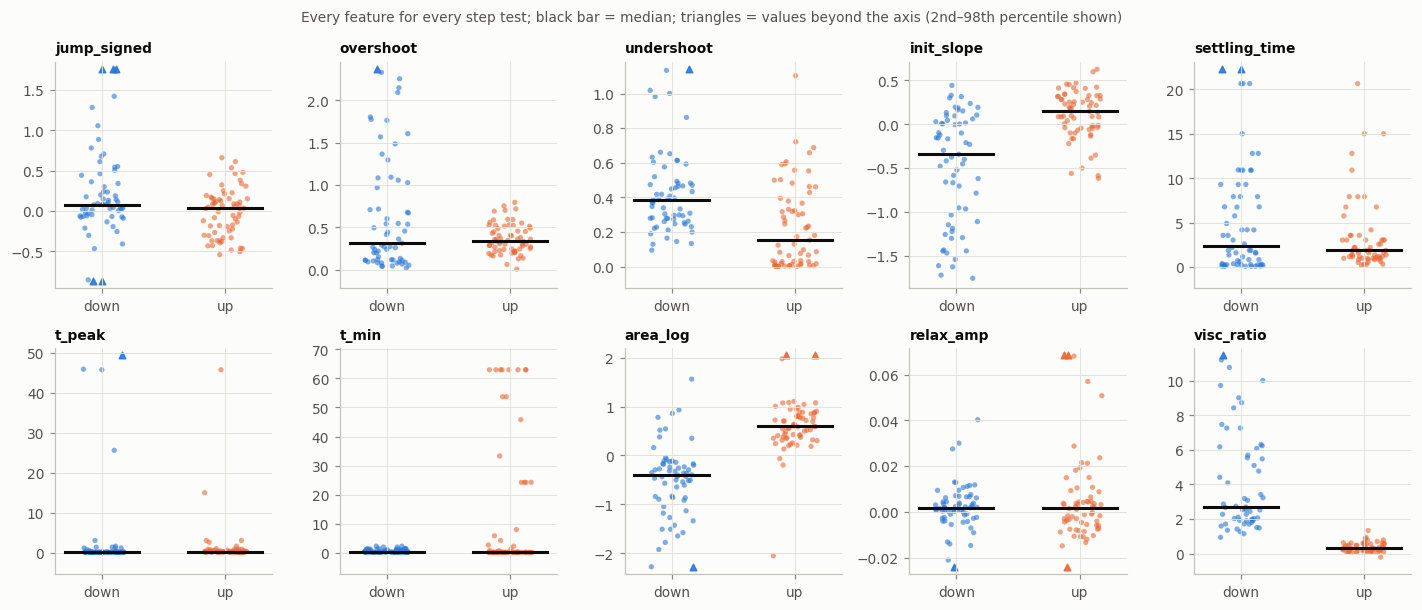

In [96]:
Q = steps[steps.qc_rate != "MISMATCH with label"]
fig, axs = plt.subplots(2, 5, figsize=(13, 5.6))
rng_ = np.random.default_rng(1)
for a, f in zip(axs.ravel(), FEATURES):
    lo, hi = np.nanpercentile(Q[f], [2, 98]); pad = 0.08 * (hi - lo if hi > lo else 1)
    for j, dirn in enumerate(["down", "up"]):
        y = Q.loc[Q.direction == dirn, f].dropna().values
        x = j + rng_.uniform(-0.18, 0.18, len(y))
        inside = (y >= lo - pad) & (y <= hi + pad)
        a.scatter(x[inside], y[inside], s=12, color=DIR_COL[dirn], alpha=0.6, edgecolor="none")
        a.scatter(x[~inside], np.clip(y[~inside], lo - pad, hi + pad), s=18, marker="^", color=DIR_COL[dirn], alpha=0.9)
        a.plot([j - 0.3, j + 0.3], [np.median(y)] * 2, color=INK, lw=2)
    a.set_xticks([0, 1], ["down", "up"]); a.set_ylim(lo - 1.5 * pad, hi + 1.5 * pad); a.set_title(f, fontsize=9)
fig.suptitle("Every feature for every step test; black bar = median; triangles = values beyond the axis (2nd–98th percentile shown)",
             fontsize=9, color=INK2)
fig.tight_layout(); fig.savefig(FIG / "02d_feature_distributions.png", dpi=200); plt.show()

**What it shows.** Pooled over all steps, the clearest up/down differences are `init_slope` (a steeper fall after step-downs), `area_log` (negative for step-downs, positive for step-ups), `undershoot` (larger for step-downs) and `visc_ratio` (above 1 for step-downs and below 1 for step-ups; this one is expected, because blood's viscosity rises when the rate falls). `jump_signed` overlaps almost completely between the two directions, which foreshadows why the planned direction rule fails in §7.2. Pooled comparisons mix different starting rates, so §7 tests direction only on matched pairs.

### 5.1 Validate the baseline and plateau against steady-shear data
If the pre-step stress and the final plateau are genuine steady states, they should agree with the independent flow curve measured on the same sample. Ratios near 1 support the feature definitions; large departures identify blocks whose baseline or plateau cannot be trusted.

**How to read this chart.** Each point is one step test. The horizontal position is the stress the separate flow-curve measurement predicts at the same shear rate; the vertical position is the stress measured in the step test. Points on the grey diagonal agree exactly; points above it are higher in the step test. Both axes are logarithmic, so equal distances mean equal *ratios*. Triangles pointing up are step-ups, triangles pointing down are step-downs.

       baseline_vs_fc  plateau_vs_fc
count          130.00         131.00
mean             1.37           1.31
std              1.17           0.48
min             -1.53           0.53
10%              0.52           1.01
50%              1.07           1.13
90%              2.60           2.00
max              8.89           4.38


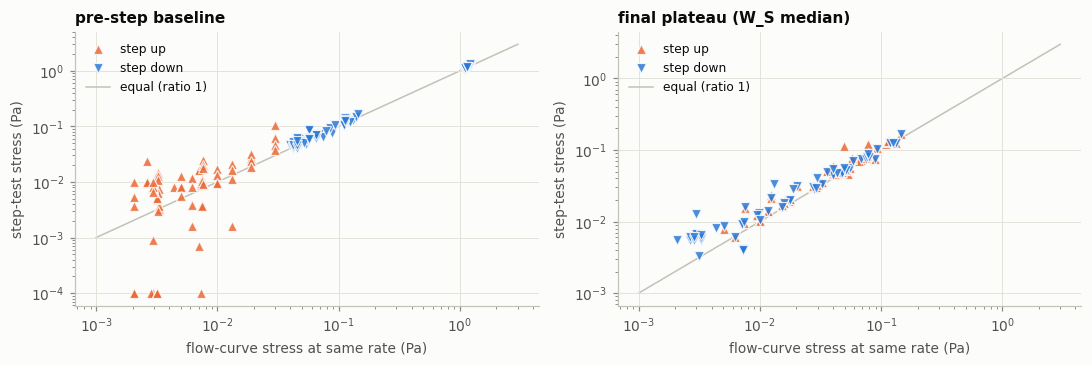

In [97]:
chk = steps[["baseline_vs_fc", "plateau_vs_fc"]].replace([np.inf, -np.inf], np.nan)
print(chk.describe(percentiles=[.1, .5, .9]).round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, (col, ref, ttl) in zip(ax, [("sigma_pre", "sigma_pre_fc", "pre-step baseline"),
                                   ("sigma_stable", "sigma_final_fc", "final plateau (W_S median)")]):
    for dirn, mk in [("up", "^"), ("down", "v")]:
        q = steps[steps.direction == dirn]
        a.loglog(q[ref], q[col].clip(lower=1e-4), mk, ms=6, alpha=0.85, color=DIR_COL[dirn], mec=SURFACE, mew=0.8, label=f"step {dirn}")
    lim = [1e-3, 3]; a.plot(lim, lim, color=AXIS, lw=1, zorder=0, label="equal (ratio 1)")
    a.set(xlabel="flow-curve stress at same rate (Pa)", ylabel="step-test stress (Pa)", title=ttl); a.legend()
fig.tight_layout(); fig.savefig(FIG / "02_baseline_plateau_vs_flowcurve.png", dpi=200); plt.show()

**Result.** The pre-step baseline agrees with the flow curve (median ratio 1.07). The final plateau is systematically **about 13 % above** the flow curve (median 1.13, 90th percentile 2.0), with the largest departures at low shear rates. The step tests and the flow curve were run at different times on the same loaded sample, so this gap reflects time-dependence (and possibly sedimentation) of the blood. Features in this notebook are therefore normalised by each step's **own** plateau σ_stable, never by the flow curve.

## 6. Relaxation models (only where justified)

Two levels of model are fitted, both on t ≥ rate settling time.

### 6.1 Empirical single exponential
σ(t) = σ∞ + A·exp(−(t − t_step)/τ). This is a descriptive check on the time scale. A fit counts as **failed / not interpretable** if it does not converge, τ sits on a bound (0.01 s or 200 s), the 95 % confidence interval of τ is wider than τ itself, or R² < 0.5. Non-monotonic responses (for example 300 → 5 s⁻¹, where stress dips, rises and then decays) are expected to fail and are logged.

### 6.2 Thixo-elasto-visco-plastic model from the papers (ethixo-EVP, version 1)
From Armstrong et al. (2021), with n = 1 and the aggregation exponent d = ½ fixed as in all four papers.

Steady state (Eqs. 10 and 16):

$$\sigma_{ss}=\lambda_{ss}\,\sigma_{y0}+\left(\lambda_{ss}\,\eta_{ST}+\eta_\infty\right)\dot\gamma,\qquad
\lambda_{ss}=\frac{t_{r2}|\dot\gamma|^{1/2}+1}{t_{r1}|\dot\gamma|+t_{r2}|\dot\gamma|^{1/2}+1}$$

Transient (Eq. 11 for stress, Eq. 13 for structure, both driven by the plastic rate γ̇ₚ):

$$\frac{1}{G}\dot\sigma=\dot\gamma-\dot\gamma_p,\qquad
\dot\gamma_p=\frac{\max(0,\,|\sigma|-\lambda\sigma_{y0})}{\lambda\eta_{ST}+\eta_\infty}\,\mathrm{sign}(\sigma)$$

$$\dot\lambda=k_\lambda\left(-t_{r1}|\dot\gamma_p|\lambda+t_{r2}|\dot\gamma_p|^{1/2}(1-\lambda)+(1-\lambda)\right)$$

The elastic modulus G is kept because the data need it: after a step down, stress first *falls* for about 1 s (elastic relaxation) before rising again as structure rebuilds. A model without G cannot produce that dip. After a step to rate γ̇₁ the structure relaxes with an effective time τ_eff ≈ 1/(k_λ·(t_{r1}γ̇₁ + t_{r2}γ̇₁^{1/2} + 1)): **faster at high final rates (breakdown) and slower at low final rates (aggregation)**, which is the asymmetry the papers report.

**Fitting procedure (as in the papers):**
1. Initial guess: fit σy0, ηST, η∞, tr1, tr2 to the flow curve with the relative cost (Eq. 17).
2. Fit all seven parameters **simultaneously** to the flow curve and every step-up and step-down of that workbook, as done for the tensorial models in the Frontiers (2022) and Sci. Rep. (2021) papers. The cost is the least-squares form of Frontiers Eq. 12, with each step normalised by its own maximum stress. The ODEs are integrated with LSODA (the papers use MATLAB's ode23s; both are stiff solvers). Two starting points are used: the stage-1 result and the papers' typical values.
3. Goodness of fit per step is the NRMSE (RMS error / maximum stress of that step). A step is **poorly fitted** if NRMSE > 10 %, or > 2× noise/maximum stress for very low-stress steps, which cannot be fitted better than the noise.
4. Compare with the literature: τ_λ = 1.13 ± 0.24 s (Frontiers 2022, 12 donors) and 0.55–0.96 s (Sci. Rep. 2021, Donor 1); G = 0.29 Pa for this same model (JNNFM 2021, Donor 3). The Frontiers G_R = 0.15 ± 0.05 Pa belongs to the tensorial t-ESSTV model and is shown only as a related reference.

This takes roughly 10–20 s per workbook.

In [98]:
def exp_model(t, s_inf, A, tau):
    return s_inf + A * np.exp(-t / tau)

def fit_exponential(b, e):
    d = b["an"]; m = d.time >= e.t_rate_settle
    t = d.time.values[m] - e.t_step; y = d.stress.values[m]
    rec = dict(step_id=b["step_id"], model="exponential")
    try:
        p0 = [np.median(y[-5:]), y[0] - np.median(y[-5:]), 1.0]
        p, cov = curve_fit(exp_model, t, y, p0=p0, bounds=([-np.inf, -np.inf, 0.01], [np.inf, np.inf, 200]), maxfev=20000)
        yhat = exp_model(t, *p); r2 = 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)
        se = np.sqrt(np.diag(cov))[2] if np.all(np.isfinite(cov)) else np.inf
        reasons = []
        if p[2] <= 0.0101 or p[2] >= 199: reasons.append("tau at bound")
        if not np.isfinite(se) or 1.96 * se > p[2]: reasons.append("tau CI wider than tau")
        if r2 < 0.5: reasons.append("R2 < 0.5")
        rec.update(s_inf=p[0], amp=p[1], tau=p[2], tau_se=se, r2=r2, rmse=np.sqrt(np.mean((y - yhat) ** 2)),
                   status="ok" if not reasons else "not interpretable", reason="; ".join(reasons))
    except Exception as err:
        rec.update(status="failed", reason=type(err).__name__)
    return rec

evs = ev.set_index("step_id")
fits_exp = pd.DataFrame([fit_exponential(b, evs.loc[b["step_id"]]) for b in blocks])
print(fits_exp.status.value_counts().to_string())
fits_exp.merge(ev[["step_id", "direction", "rate_from", "rate_to"]]).groupby(["direction", "rate_to"]).status.agg(
    lambda s: f"{(s == 'ok').sum()}/{len(s)} ok").unstack(0).fillna("")

status
not interpretable    69
ok                   67


direction,down,up
rate_to,,
0.10,14/28 ok,
0.25,2/6 ok,1/6 ok
0.50,2/6 ok,4/12 ok
1.00,0/7 ok,3/11 ok
2.50,3/7 ok,3/12 ok
5.00,5/6 ok,18/18 ok
10.00,2/5 ok,4/4 ok
20.00,2/4 ok,4/4 ok


**How to read this chart.** One bar per group of step tests with the same direction and final rate. The green part counts the tests where a single exponential gives a usable time constant τ; the orange part counts the tests where it does not (τ on a bound, an uncertainty wider than τ, or R² < 0.5). The number at the end is usable / total.

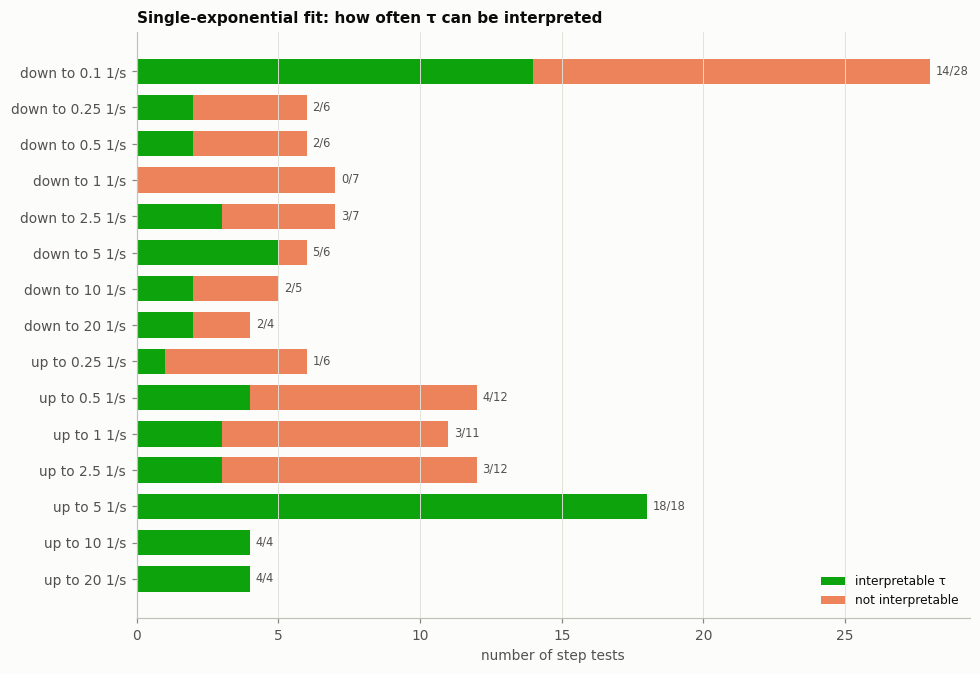

In [99]:
E_ = fits_exp.merge(ev[["step_id", "direction", "rate_to"]])
E_["ok"] = E_.status == "ok"
T_ = E_.groupby(["direction", "rate_to"]).ok.agg(["sum", "size"]).reset_index()
T_["name"] = T_.direction + " to " + T_.rate_to.map("{:g}".format) + " 1/s"
T_ = T_.sort_values(["direction", "rate_to"])
fig, ax = plt.subplots(figsize=(9, 0.32 * len(T_) + 1.4))
y = np.arange(len(T_))
ax.barh(y, T_["sum"], color=STATUS["good"], height=0.7, label="interpretable τ")
ax.barh(y, T_["size"] - T_["sum"], left=T_["sum"], color=STATUS["serious"], height=0.7, label="not interpretable")
for yi, k, n in zip(y, T_["sum"], T_["size"]):
    ax.text(n + 0.2, yi, f"{int(k)}/{int(n)}", va="center", fontsize=7.5, color=INK2)
ax.set_yticks(y, T_.name); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set(xlabel="number of step tests", title="Single-exponential fit: how often τ can be interpreted")
ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "03a_exponential_fit_status.png", dpi=200); plt.show()

**What it shows.** The single exponential works for step-ups to high rates (every step up to 5, 10 or 20 s⁻¹ gives a usable τ) and for most steps down to 5 s⁻¹, but poorly elsewhere: none of the steps down to 1 s⁻¹, about half of those down to 0.1 s⁻¹, and a third or fewer of the step-ups to 0.25–2.5 s⁻¹. In those tests the response is either non-monotonic (dip, then recovery) or too small compared with the noise. This is why a single-exponential τ is not recommended as a transient metric.

In [100]:
from scipy.integrate import solve_ivp

def lam_ss(g, tr1, tr2):                                   # Eq. 16
    g = np.abs(g); return (tr2 * g ** D_EXP + 1) / (tr1 * g + tr2 * g ** D_EXP + 1)

def sigma_ss(g, p):                                        # Eq. 10
    sy, eta_st, eta_inf, tr1, tr2 = p[:5]
    lam = lam_ss(g, tr1, tr2); return lam * sy + (lam * eta_st + eta_inf) * g

def simulate_step(t_eval, g0, g1, t_step, p):
    """ethixo-EVP version 1: Eq. 11 (n = 1) for stress and Eq. 13 for structure, driven by the plastic rate.
    Starts from steady state at the initial rate g0; the rate switches to g1 at t_step."""
    sy, eta_st, eta_inf, tr1, tr2, G, k_lam = p
    def rhs(t, z):
        s, lam = z
        g = g1 if t >= t_step else g0
        gp = max(0.0, abs(s) - lam * sy) / (lam * eta_st + eta_inf) * np.sign(s)     # plastic shear rate
        agp = abs(gp)
        return [G * (g - gp), k_lam * (-tr1 * agp * lam + tr2 * agp ** D_EXP * (1 - lam) + (1 - lam))]
    z0 = [sigma_ss(g0, p), lam_ss(g0, tr1, tr2)]
    sol = solve_ivp(rhs, (0, t_eval[-1]), z0, t_eval=t_eval, method="LSODA", rtol=1e-6, atol=[1e-8, 1e-8],
                    first_step=1e-5, max_step=t_eval[-1] / 20)
    if not sol.success or sol.y.shape[1] != len(t_eval):
        return np.full(len(t_eval), np.nan), np.full(len(t_eval), np.nan)
    return sol.y[0], sol.y[1]

def step_series(b, e):
    """Stress after the instrument window, with time measured from the step."""
    d = b["an"]; m = d.time >= e.t_rate_settle
    return d.time.values[m] - e.t_step, d.stress.values[m]

#                  sigma_y0  eta_ST  eta_inf  tr1   tr2    G     k_lambda
LOW = np.log([1e-6, 1e-4, 1e-4, 1e-3, 1e-4, 1e-3, 1e-3])
HIGH = np.log([1.0, 1.0, 0.05, 1e3, 1e3, 1e2, 1e2])
P_LIT = np.array([0.003, 0.02, 0.003, 0.5, 0.2, 0.3, 1.0])   # start near the papers' reported values

def fit_steady(x, y):
    """Stage 1 (initial guess, as in the papers): Eq. 17 relative cost on the flow curve only."""
    r = least_squares(lambda q: (y - sigma_ss(x, np.exp(q))) / y, np.log(P_LIT[:5]), bounds=(LOW[:5], HIGH[:5]))
    return np.exp(r.x)

def joint_residuals(q, x, y, series):
    """Stage 2: least-squares form of Frontiers Eq. 12 -- flow-curve residuals normalised point-wise, each step's
    residuals by that step's maximum stress, and every experiment weighted equally."""
    p = np.exp(q)
    r = [(y - sigma_ss(x, p)) / y / np.sqrt(len(y))]
    for t, s, g0, g1, ts in series:
        f, _ = simulate_step(t, g0, g1, ts, p)
        rr = (s - f) / np.max(np.abs(s)) / np.sqrt(len(s) * len(series))
        r.append(np.where(np.isfinite(rr), rr, 10.0))           # solver failure -> large penalty
    return np.concatenate(r)

model_rows, model_curves = [], {}
for (wb, sh), grp in ev[ev.qc_rate != "MISMATCH with label"].groupby(["workbook", "storage_h"]):
    fc = flow_curve_for(wb, sh)
    if fc is None: continue
    x, y = fc["rate"][fc["stress"] > 0], fc["stress"][fc["stress"] > 0]
    ser = []
    for sid in grp.step_id:
        e = evs.loc[sid]; d = next(b for b in blocks if b["step_id"] == sid)["an"]
        m = d.time >= e.t_rate_settle
        ser.append((d.time.values[m], d.stress.values[m], e.rate_from, e.rate_to, e.t_step))
    best = None
    for st in (np.r_[fit_steady(x, y), P_LIT[5:]], P_LIT):
        r = least_squares(joint_residuals, np.log(st), args=(x, y, ser), bounds=(LOW, HIGH), max_nfev=300)
        if best is None or r.cost < best.cost: best = r
    p = np.exp(best.x)
    # conditional profile of k_lambda (other parameters held at the optimum): k values within 10 % of the minimum cost
    grid = np.exp(np.linspace(LOW[6], HIGH[6], 41))
    prof = np.array([np.sum(joint_residuals(np.log(np.r_[p[:6], kk]), x, y, ser) ** 2) for kk in grid])
    within = grid[prof <= prof.min() * 1.10]
    per = []
    for sid, (t, s, g0, g1, ts) in zip(grp.step_id, ser):
        f, lam = simulate_step(t, g0, g1, ts, p)
        nrmse = np.sqrt(np.mean(((s - f) / np.max(np.abs(s))) ** 2))
        per.append(dict(step_id=sid, nrmse_model=nrmse,
                        fit_threshold=max(MODEL_MAX_NRMSE, 2 * NOISE_PA / np.max(np.abs(s))),
                        tau_eff=1 / (p[6] * (p[3] * g1 + p[4] * g1 ** D_EXP + 1))))
        model_curves[sid] = (t - ts, f, lam)
    per = pd.DataFrame(per).set_index("step_id")
    sel = steps.step_id.isin(per.index)
    for c in per.columns:
        steps.loc[sel, c] = steps.loc[sel, "step_id"].map(per[c]).values
    rss = np.sum(best.fun ** 2); n = len(best.fun); k_par = 7
    model_rows.append(dict(workbook=wb, sample=grp["sample"].iloc[0], storage_h=sh, n_steps=len(ser),
                           sigma_y0=p[0], eta_ST=p[1], eta_inf=p[2], tr1=p[3], tr2=p[4], G=p[5], k_lambda=p[6],
                           tau_lambda=1 / p[6], tau_lambda_lo=1 / within.max(), tau_lambda_hi=1 / within.min(),
                           Fcost_ss=np.sqrt(np.mean(((y - sigma_ss(x, p)) / y) ** 2)),
                           median_step_nrmse=per.nrmse_model.median(),
                           steps_fitted_ok=f"{(per.nrmse_model <= per.fit_threshold).sum()}/{len(per)}",
                           AIC=n * np.log(rss / n) + 2 * k_par, BIC=n * np.log(rss / n) + k_par * np.log(n),
                           k_at_bound=bool(best.x[6] <= LOW[6] + 0.05 or best.x[6] >= HIGH[6] - 0.05)))

models = pd.DataFrame(model_rows)
models.to_csv(OUT / "relaxation_fits.csv", index=False)
models.drop(columns="workbook").round(4)

,sample,storage_h,n_steps,sigma_y0,eta_ST,eta_inf,tr1,tr2,G,k_lambda,tau_lambda,tau_lambda_lo,tau_lambda_hi,Fcost_ss,median_step_nrmse,steps_fitted_ok,AIC,BIC,k_at_bound
0,12FEB20,0.0,9,0.0033,0.0273,0.0029,1.3776,0.7721,0.3425,0.7194,1.3900,0.4217,3.1623,0.0929,0.1578,3/9,-3708.1172,-3679.9871,False
1,14DEC,0.0,5,0.0006,0.0282,0.0036,0.6157,0.1031,0.2672,5.7426,0.1741,0.0562,0.3162,0.0633,0.1714,0/5,-2064.3593,-2040.1720,False
2,14MAR19,0.0,9,0.0009,0.0075,0.0032,0.0863,0.0131,0.2458,4.4382,0.2253,0.0562,1.3335,0.1438,0.1563,3/9,-3580.5953,-3552.5164,False
3,27FEB19,0.0,10,0.0018,0.0170,0.0032,0.3972,0.1337,0.2469,2.6839,0.3726,0.1778,0.7499,0.0655,0.1138,5/10,-4474.6115,-4445.8003,False
4,9MAY19,0.0,9,0.0055,0.0263,0.0024,1.2916,1.3176,0.3081,0.5103,1.9596,1.3335,2.3714,0.0687,0.0877,6/9,-4025.5313,-3997.4525,False
5,APR18,0.0,6,0.0070,0.0805,0.0050,1.4686,0.4997,0.4673,2.2750,0.4396,0.3162,0.5623,0.0328,0.0786,6/6,-3041.1903,-3015.5983,False
6,FEB18,0.0,10,0.0000,0.0526,0.0035,1.4883,0.3556,0.3211,6.1420,0.1628,0.0562,0.4217,0.0656,0.1241,3/10,-4592.7988,-4563.9107,False
7,JUL18,0.0,14,0.0000,0.0403,0.0033,2.4512,0.7206,0.1883,0.9009,1.1099,0.3162,2.3714,0.0611,0.1215,4/14,-6483.9843,-6452.8090,False
8,JUN18,0.0,14,0.0000,0.0225,0.0032,0.7221,0.1273,0.1885,1.5377,0.6503,0.1000,1.7783,0.0793,0.1162,6/14,-6326.4848,-6295.2764,False
9,NOV18,0.0,6,0.0008,0.0218,0.0035,0.4382,0.0506,0.2566,4.0772,0.2453,0.1000,0.7499,0.0529,0.1373,1/6,-2615.5396,-2590.1211,False


In [101]:
fails = pd.concat([
    fits_exp[fits_exp.status != "ok"].merge(ev[["step_id", "sample", "label"]])[["step_id", "sample", "label", "model", "status", "reason"]],
    steps[steps.nrmse_model > steps.fit_threshold].assign(model="ethixo-EVP", status="poor fit",
                                       reason=lambda x: "NRMSE = " + x.nrmse_model.round(3).astype(str))[
        ["step_id", "sample", "label", "model", "status", "reason"]],
    models[models.k_at_bound].assign(step_id="(all)", label="(workbook)", model="ethixo-EVP",
                                     status="k_lambda at bound", reason="not identifiable")[
        ["step_id", "sample", "label", "model", "status", "reason"]]])
fails.to_csv(OUT / "fit_failure_log.csv", index=False)
print(f"{len(fails)} entries in the failure log")
fails.groupby(["model", "status"]).size()

151 entries in the failure log


model        status           
ethixo-EVP   poor fit             82
exponential  not interpretable    69
dtype: int64

### 6.3 Validation against the literature parameters

**How to read this chart.** One row per blood sample (and storage time). Left: the fitted structural time τ_λ, with bars showing the range of values that fit almost as well (the conditional profile interval: a wide bar means the data pin τ_λ down poorly). The green band is the published 12-donor mean ± 2 SD. Right: the fitted elastic modulus G, with the green band for the related t-ESSTV model and the black line for the same model's published value.

tau_lambda (this data): median 0.65 s, IQR 0.25-1.19 s  (n = 13 workbook x storage fits, 11 workbooks)
   literature: 1.13 +- 0.24 s (Frontiers 2022, 12 donors); 0.55-0.96 s (Sci. Rep. 2021, Donor 1)
   fits within literature mean +- 2 SD: 5 / 13
G (this data): median 0.267 Pa, range 0.188-0.470 Pa;  literature: G = 0.29 Pa (same model, JNNFM 2021), G_R = 0.15 +- 0.05 Pa (t-ESSTV, Frontiers 2022)
steps fitted within threshold: 51 / 133

fit quality by final shear rate (median NRMSE):
direction   down     up
rate_to                
0.10       0.192    NaN
0.25       0.169  0.205
0.50       0.123  0.201
1.00       0.091  0.119
2.50       0.044  0.104
5.00       0.135  0.112
10.00      0.077  0.072
20.00      0.051  0.080


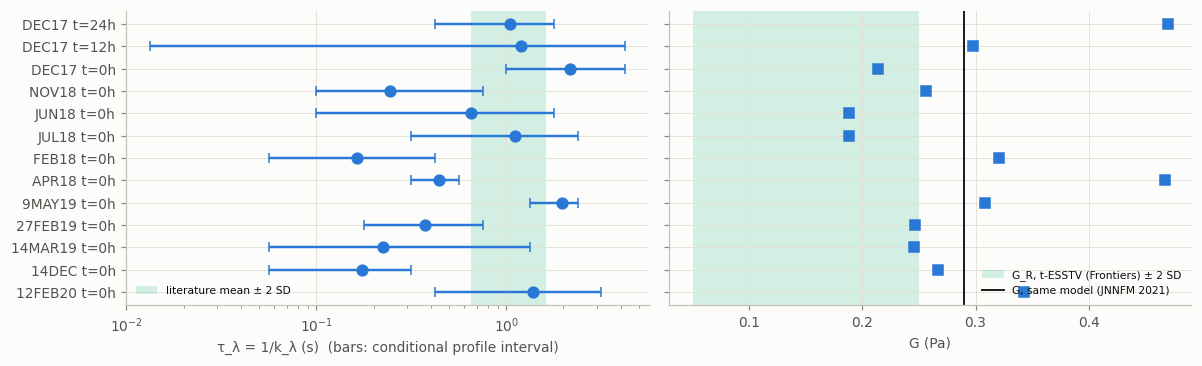

In [102]:
mu, sd = TAU_LAMBDA_LIT
okm = models[~models.k_at_bound]
print(f"tau_lambda (this data): median {okm.tau_lambda.median():.2f} s, IQR {okm.tau_lambda.quantile(.25):.2f}-"
      f"{okm.tau_lambda.quantile(.75):.2f} s  (n = {len(okm)} workbook x storage fits, {okm['sample'].nunique()} workbooks)")
print(f"   literature: {mu} +- {sd} s (Frontiers 2022, 12 donors); 0.55-0.96 s (Sci. Rep. 2021, Donor 1)")
print(f"   fits within literature mean +- 2 SD: {((okm.tau_lambda - mu).abs() <= 2 * sd).sum()} / {len(okm)}")
print(f"G (this data): median {okm.G.median():.3f} Pa, range {okm.G.min():.3f}-{okm.G.max():.3f} Pa"
      f";  literature: G = {G_LIT_V1} Pa (same model, JNNFM 2021), G_R = {G_LIT_R[0]} +- {G_LIT_R[1]} Pa (t-ESSTV, Frontiers 2022)")
print(f"steps fitted within threshold: {(steps.nrmse_model <= steps.fit_threshold).sum()} / {steps.nrmse_model.notna().sum()}")
print("\nfit quality by final shear rate (median NRMSE):")
print(steps.groupby(["direction", "rate_to"]).nrmse_model.median().unstack(0).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
yy = np.arange(len(models)); names = [f'{s_} t={int(h)}h' for s_, h in zip(models["sample"], models.storage_h)]
ax[0].errorbar(models.tau_lambda, yy, xerr=[models.tau_lambda - models.tau_lambda_lo, models.tau_lambda_hi - models.tau_lambda],
               fmt="o", ms=7, capsize=3, color=PAL[0])
ax[0].axvspan(mu - 2 * sd, mu + 2 * sd, color=WIN_S, alpha=0.18, lw=0, label="literature mean ± 2 SD")
ax[0].set(xscale="log", xlabel="τ_λ = 1/k_λ (s)  (bars: conditional profile interval)"); ax[0].legend(loc="lower left", fontsize=7)
ax[1].plot(models.G, yy, "s", ms=7, color=PAL[0])
ax[1].axvspan(G_LIT_R[0] - 2 * G_LIT_R[1], G_LIT_R[0] + 2 * G_LIT_R[1], color=WIN_S, alpha=0.18, lw=0, label="G_R, t-ESSTV (Frontiers) ± 2 SD")
ax[1].axvline(G_LIT_V1, color=INK, lw=1.2, label="G, same model (JNNFM 2021)")
ax[1].set(xlabel="G (Pa)"); ax[1].legend(loc="lower right", fontsize=7)
ax[0].set_yticks(yy, names)
fig.tight_layout(); fig.savefig(FIG / "03_tau_lambda_vs_literature.png", dpi=200); plt.show()

### 6.4 Representative fits (papers' figure layout)
Step-downs from 5 s⁻¹ and step-ups from 0.25 s⁻¹, with the model's structure parameter λ(t) underneath, as in Armstrong et al. (2021) Figs. 3–4 and Frontiers (2022) Fig. 5. The shaded bands are the transient (orange) and stable (green) windows.

**How to read this chart.** Top row: points are measured stress, lines are the fitted model, one colour per step size. Bottom row: the model's structure parameter λ(t), from 0 (rouleaux fully broken) to 1 (fully structured), for the same steps. Time is measured from the moment of the step, on a log scale. The tinted bands mark the fixed transient and stable windows.

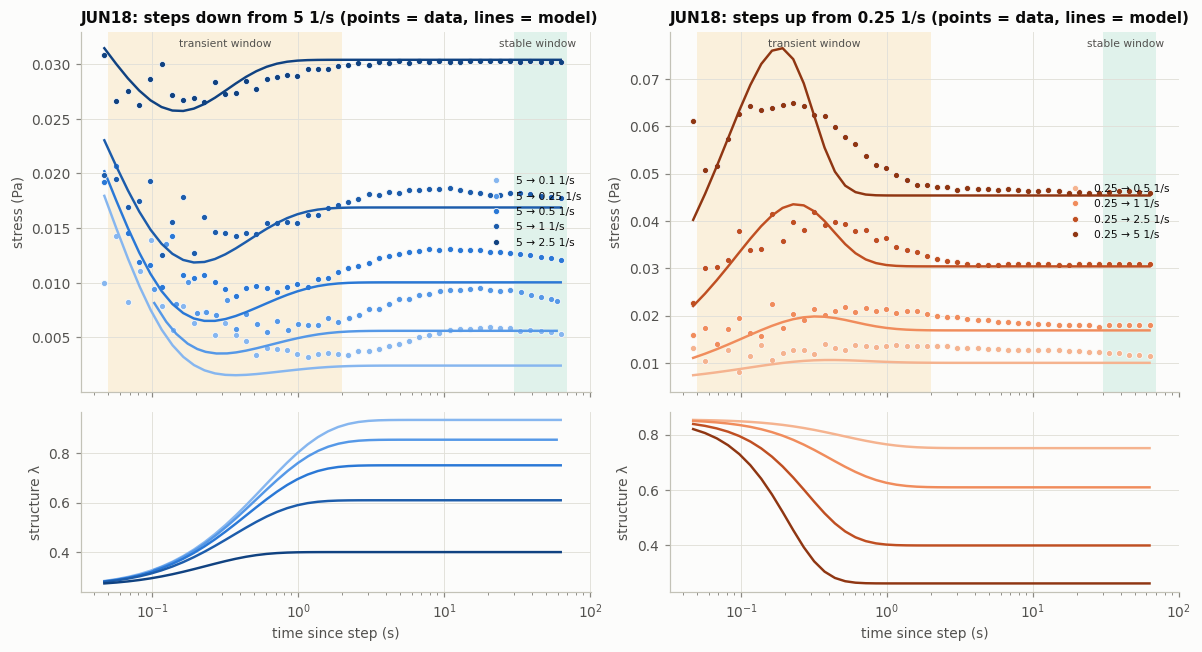

In [103]:
def plot_family(sample, storage_h=0.0, start_down=5.0, start_up=0.25, fname="04_representative_fits.png"):
    q = steps[(steps["sample"] == sample) & (steps.storage_h == storage_h)]
    fig, ax = plt.subplots(2, 2, figsize=(11, 6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    for col, (dirn, g0) in enumerate([("down", start_down), ("up", start_up)]):
        sub = q[(q.direction == dirn) & np.isclose(q.rate_from, g0)].sort_values("rate_to")
        for i, (_, r) in enumerate(sub.iterrows()):
            b = next(bb for bb in blocks if bb["step_id"] == r.step_id)
            t, y = step_series(b, r)
            ax[0, col].semilogx(t, y, "o", ms=4, color=shades(dirn, len(sub))[i], mec=SURFACE, mew=0.5, label=f"{g0:g} → {r.rate_to:g} 1/s")
            if r.step_id in model_curves:
                tm, fm, lam = model_curves[r.step_id]
                ax[0, col].semilogx(tm, fm, "-", color=shades(dirn, len(sub))[i], lw=1.6)
                ax[1, col].semilogx(tm, lam, "-", color=shades(dirn, len(sub))[i])
        shade_windows(ax[0, col])
        ax[0, col].set(title=f"{sample}: steps {dirn} from {g0:g} 1/s (points = data, lines = model)", ylabel="stress (Pa)")
        ax[0, col].legend(fontsize=7, loc="center right"); ax[1, col].set(xlabel="time since step (s)", ylabel="structure λ")
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=200); plt.show()

plot_family("JUN18")

**How to read this chart.** First chart: the same layout as the data map, but each cell's shade shows how far the model is from the data for that step (NRMSE, the typical error as a fraction of the step's largest stress). White or pale = close fit; dark blue = poor fit; × = worse than the pre-set threshold. Second chart: one small panel per blood sample, with stress divided by each step's own stable value so that all samples share one scale (1 = steady state). Points are data, lines the model; blue is a step down from 5 s⁻¹, orange a step up to 5 s⁻¹.

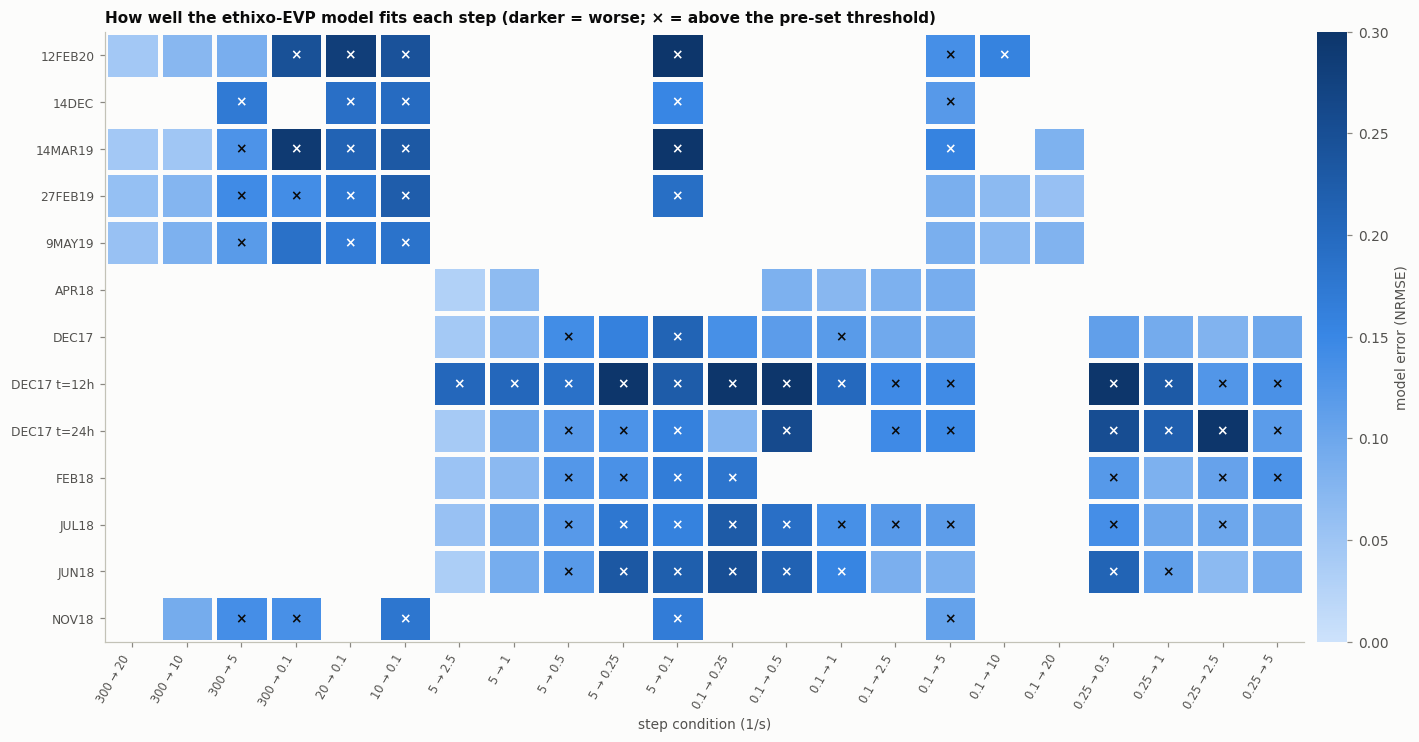

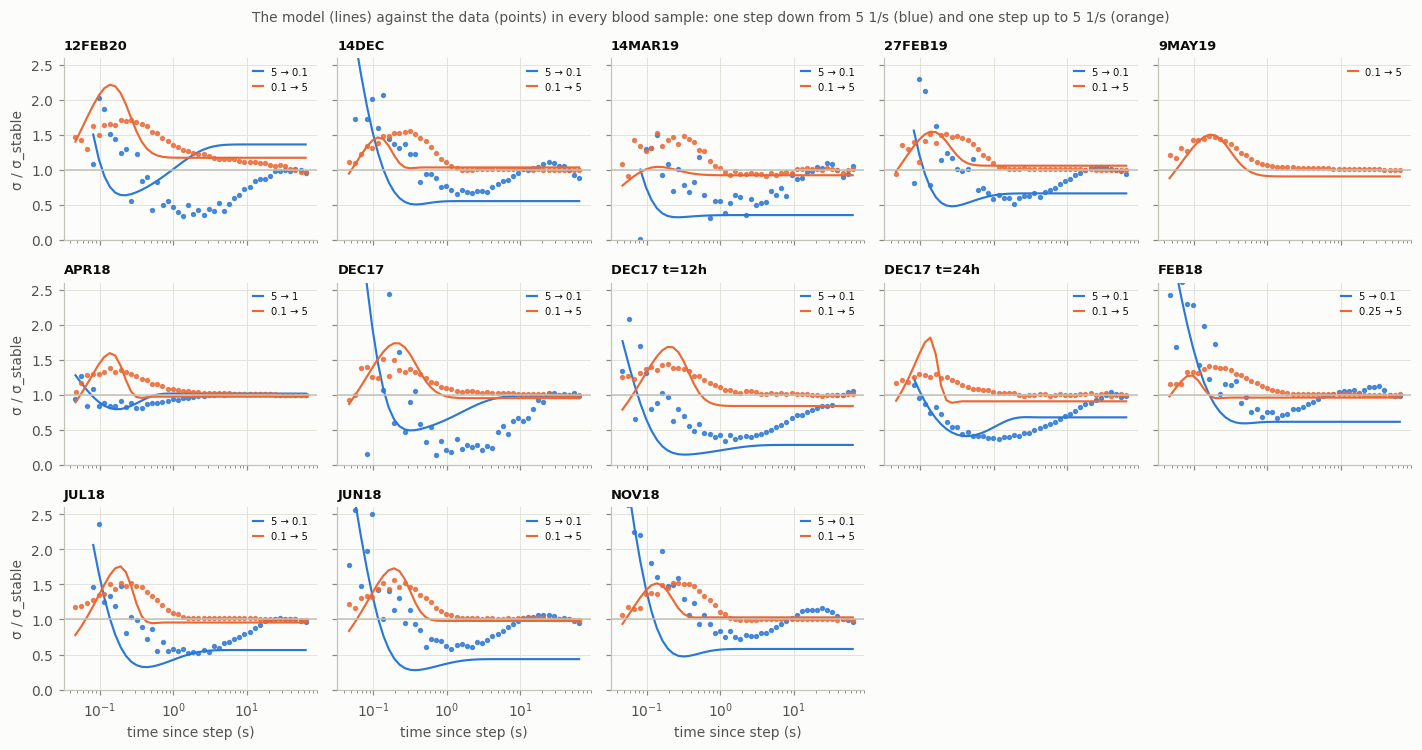

In [104]:
from matplotlib.colors import LinearSegmentedColormap
H_ = steps[steps.nrmse_model.notna()].assign(unit=lambda q: unit_name(q), cond=lambda q: cond_name(q))
Hm = H_.pivot_table(index="unit", columns="cond", values="nrmse_model")
Hm = Hm.reindex(index=[u for u in UNIT_ORDER if u in Hm.index], columns=[c for c in COND_ORDER if c in Hm.columns])
fig, ax = plt.subplots(figsize=(13, 0.34 * len(Hm) + 2.4))
im = ax.pcolormesh(Hm.values, cmap=LinearSegmentedColormap.from_list("blues", BLUES), vmin=0, vmax=0.3,
                   edgecolors=SURFACE, linewidth=2)
bad_ = H_[H_.nrmse_model > H_.fit_threshold]
for _, r in bad_.iterrows():
    if r.unit in Hm.index and r.cond in Hm.columns:
        ax.text(list(Hm.columns).index(r.cond) + 0.5, list(Hm.index).index(r.unit) + 0.5, "×", ha="center", va="center",
                fontsize=9, color="white" if r.nrmse_model > 0.15 else INK, fontweight="bold")
ax.set_xticks(np.arange(Hm.shape[1]) + 0.5, Hm.columns, rotation=60, ha="right", fontsize=7.5)
ax.set_yticks(np.arange(Hm.shape[0]) + 0.5, Hm.index, fontsize=8); ax.invert_yaxis(); ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01, fraction=0.03); cb.set_label("model error (NRMSE)", color=INK2); cb.outline.set_visible(False)
ax.set(xlabel="step condition (1/s)", title="How well the ethixo-EVP model fits each step (darker = worse; × = above the pre-set threshold)")
fig.tight_layout(); fig.savefig(FIG / "04b_model_fit_quality.png", dpi=200); plt.show()

# same two protocols in every blood sample, normalised by each step's own stable stress
units = [u for u in UNIT_ORDER]
fig, axs = plt.subplots(int(np.ceil(len(units) / 5)), 5, figsize=(13, 2.3 * np.ceil(len(units) / 5)), sharex=True, sharey=True)
for a, u in zip(axs.ravel(), units):
    q = H_[H_.unit == u] if u in set(H_.unit) else H_.iloc[:0]
    down = q[(q.direction == "down") & np.isclose(q.rate_from, 5)].sort_values("rate_to").head(1)
    upq = q[(q.direction == "up") & np.isclose(q.rate_to, 5)].sort_values("rate_from").head(1)
    for rr in (down, upq):
        if not len(rr): continue
        rr = rr.iloc[0]; b = next(bb for bb in blocks if bb["step_id"] == rr.step_id)
        t, y = step_series(b, rr); tm, fm, _ = model_curves[rr.step_id]
        a.semilogx(t, y / rr.sigma_stable, "o", ms=2.5, color=DIR_COL[rr.direction], alpha=0.8)
        a.semilogx(tm, fm / rr.sigma_stable, "-", color=DIR_COL[rr.direction], lw=1.4,
                   label=f"{rr.rate_from:g} → {rr.rate_to:g}")
    a.axhline(1, color=AXIS, lw=1); a.set_title(u, fontsize=8.5); a.set_ylim(0, 2.6)
    if len(down) or len(upq): a.legend(fontsize=6.5, loc="upper right", handlelength=1)
for a in axs.ravel()[len(units):]: a.axis("off")
for a in axs[-1]: a.set_xlabel("time since step (s)")
for a in axs[:, 0]: a.set_ylabel("σ / σ_stable")
fig.suptitle("The model (lines) against the data (points) in every blood sample: one step down from 5 1/s (blue) and one step up to 5 1/s (orange)",
             fontsize=9, color=INK2)
fig.tight_layout(); fig.savefig(FIG / "04c_model_all_samples.png", dpi=200); plt.show()

**What it shows.** The model fits large steps between high rates well (pale cells such as 300 → 20 and 300 → 10 s⁻¹) and fits worst on steps that end at low rates (0.1–0.25 s⁻¹), and on the DEC17 12 h sample. The small multiples show why. For step-ups (orange), the model reproduces the overshoot and its timing reasonably well. For step-downs (blue), the model levels off within about 1 s at a value *below* the data, while the measured stress keeps climbing for 10–60 s until it reaches its plateau. That slow recovery is a second, slower process that a model with a single structure parameter cannot reproduce.

**Result (relaxation models).**
* **Single exponential:** only 49 % of steps give an interpretable τ, so it is classed **unusable** as a transient metric. Step-down responses are non-monotonic (an elastic dip, then structural recovery), which one exponential cannot describe.
* **ethixo-EVP:** converges for all 13 workbook × storage-time sets with no parameter on a bound. **τ_λ has a median of 0.64 s (IQR 0.27–1.16 s)**, the same order as the literature (1.13 ± 0.24 s; 0.55–0.96 s), with 5 of 13 fits inside the literature mean ± 2 SD. **G has a median of 0.27 Pa (range 0.19–0.47 Pa)**, close to the 0.29 Pa the JNNFM paper reports for the same model. This independently reproduces the papers' parameter scale on the client data.
* **Where it fails:** fits are good at high final rates (median NRMSE 0.05–0.08 for final rates ≥ 10 s⁻¹) and poor at low final rates (0.17–0.21 at 0.1–0.25 s⁻¹). The figure shows why: after a step down, stress keeps drifting for 10–60 s, a process slower than the model's single structural time scale. This is consistent with the multi-time-scale thixotropy the JNNFM paper discusses (Wei et al., ML-IKH), and a single-λ model cannot capture it. Only 50 of 133 steps (38 %) are fitted within the pre-set threshold, so **per-step model outputs are not interpreted**; only the per-workbook τ_λ and G are used.

## 7. Do the features distinguish magnitude, direction and phase?

**Independent unit = workbook.** Each question is answered in two stages: a statistic within each workbook, then a test across workbooks (sign test or Wilcoxon signed-rank). With about 10 workbooks, all results are **exploratory** and are reported with effect sizes and counts, not just p-values.

Measurements flagged `MISMATCH with label` are excluded. Measurements without a defensible stable state are kept but marked, because features normalised by σ_stable are less reliable for them.

In [105]:
A = steps[steps.qc_rate != "MISMATCH with label"].copy()
A["unit"] = A["sample"] + "_t" + A.storage_h.astype(int).astype(str)     # workbook x storage time
print(f"analysis set: {len(A)} steps, {A['sample'].nunique()} workbooks (independent units), {A.unit.nunique()} workbook x storage units")

def sign_test(x):
    x = np.asarray(x)[np.isfinite(x) & (np.asarray(x) != 0)]
    if len(x) == 0: return np.nan, 0, 0
    k = (x > 0).sum(); return stats.binomtest(k, len(x), 0.5).pvalue, k, len(x)

analysis set: 133 steps, 11 workbooks (independent units), 13 workbook x storage units


### 7.1 Step magnitude
Within each workbook, steps are grouped into **families that share a starting rate** (for example 5 → 2.5, 1, 0.5, 0.25, 0.1 s⁻¹). This holds the starting state fixed, so only the magnitude changes. For each family with at least three steps, the Spearman correlation ρ between |log₁₀ ratio| and each feature is computed. The ρ values are averaged per workbook, and a sign test across workbooks asks whether the relation has a consistent direction.

**How to read the magnitude chart (after the table).** Each small panel is one feature; the top row shows step-downs (blue), the bottom row step-ups (orange). The horizontal axis is step size as |log₁₀(final rate / initial rate)|, so 1 means a ten-fold change and 2 a hundred-fold change. Each line connects the steps of one *family*: the same blood sample, the same starting rate, different step sizes. If a feature encodes magnitude, the lines slope the same way.

In [106]:
rows = []
for (unit, g0, dirn), fam in A.groupby(["unit", "rate_from", "direction"]):
    if len(fam) < 3: continue
    for f in FEATURES:
        x, y = fam.log10_ratio.abs(), fam[f]
        ok = np.isfinite(y)
        if ok.sum() >= 3 and y[ok].nunique() > 1:
            rows.append(dict(unit=unit, sample=fam["sample"].iloc[0], family=f"{g0:g}->*", direction=dirn,
                             feature=f, n=ok.sum(), rho=stats.spearmanr(x[ok], y[ok])[0]))
mag = pd.DataFrame(rows)
per_wb = mag.groupby(["feature", "direction", "sample"]).rho.mean().reset_index()
res_mag = []
for (f, dirn), g in per_wb.groupby(["feature", "direction"]):
    p, k, n = sign_test(g.rho)
    res_mag.append(dict(feature=f, direction=dirn, n_workbooks=n, median_rho=g.rho.median(),
                        workbooks_rho_pos=k, sign_test_p=p, families=int((mag.feature.eq(f) & mag.direction.eq(dirn)).sum())))
res_mag = pd.DataFrame(res_mag).sort_values(["direction", "sign_test_p"])
res_mag.to_csv(OUT / "result_magnitude.csv", index=False)
res_mag.round(3)

,feature,direction,n_workbooks,median_rho,workbooks_rho_pos,sign_test_p,families
12,t_min,down,9,0.900,9,0.004,11
16,undershoot,down,8,1.000,8,0.008,10
18,visc_ratio,down,8,1.000,8,0.008,10
14,t_peak,down,9,0.600,8,0.039,11
6,overshoot,down,8,0.800,7,0.070,10
0,area_log,down,8,-0.933,2,0.289,10
2,init_slope,down,8,-0.250,4,1.000,10
4,jump_signed,down,8,0.317,4,1.000,10
8,relax_amp,down,8,0.150,4,1.000,10
10,settling_time,down,9,-0.200,4,1.000,11


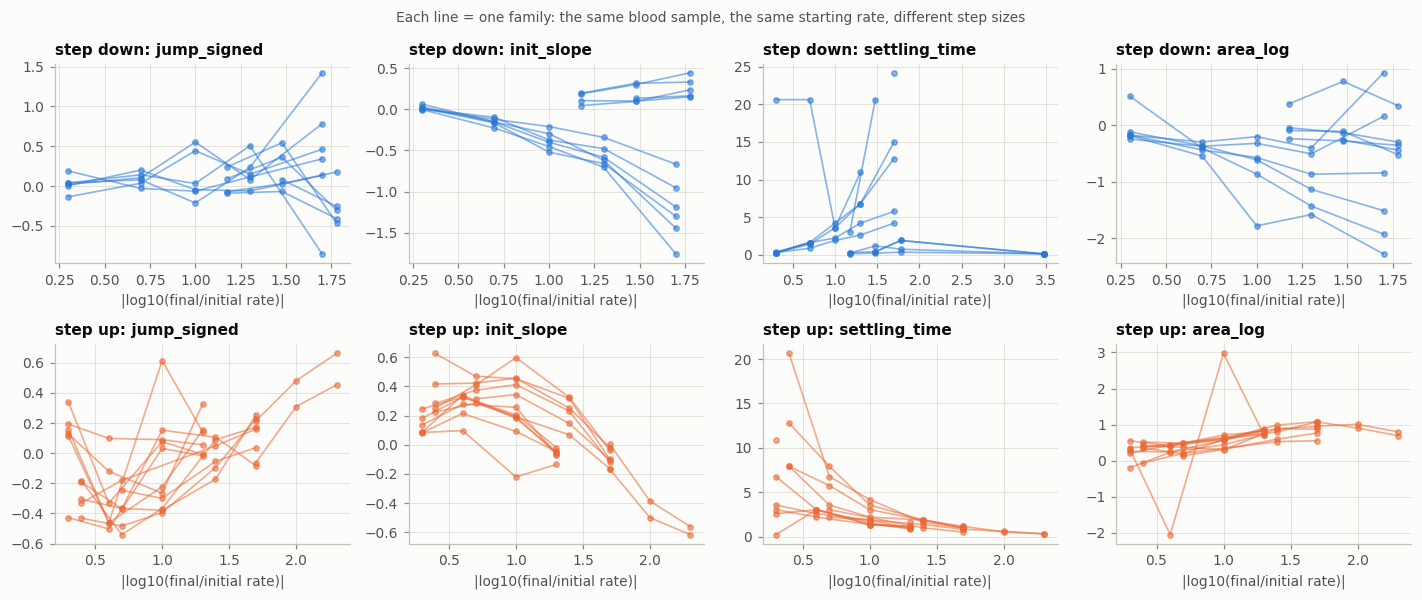

In [107]:
show = ["jump_signed", "init_slope", "settling_time", "area_log"]
fig, ax = plt.subplots(2, len(show), figsize=(13, 5.5))
for row, dirn in enumerate(["down", "up"]):
    for col, f in enumerate(show):
        a = ax[row, col]
        for i, ((unit, g0), fam) in enumerate(A[A.direction == dirn].groupby(["unit", "rate_from"])):
            if len(fam) < 3: continue
            fam = fam.sort_values("log10_ratio")
            a.plot(fam.log10_ratio.abs(), fam[f], "o-", ms=3.5, lw=1.1, alpha=0.55, color=DIR_COL[dirn])
        a.set(title=f"step {dirn}: {f}", xlabel="|log10(final/initial rate)|")
fig.suptitle("Each line = one family: the same blood sample, the same starting rate, different step sizes", fontsize=9, color=INK2)
fig.tight_layout(); fig.savefig(FIG / "05_magnitude.png", dpi=200); plt.show()

**Result (magnitude).** Magnitude is clearly encoded, but by different features for each direction:
* **Step-downs** (8–9 workbooks): a larger drop in rate gives a **deeper undershoot** (ρ = 1.0 in 8/8 workbooks), a **later minimum** `t_min` (9/9) and a larger **viscosity ratio** (8/8).
* **Step-ups** (7 workbooks): a larger rise gives a **larger overshoot** and **signed jump** (7/7), a **steeper initial decay** and **faster settling** (7/7).
* `area_log` is not consistent for either direction.

With 7–9 independent workbooks, p ≈ 0.004–0.016 is the smallest a sign test can give, so these are strong *within this dataset* but still exploratory.

### 7.2 Step direction — matched reverse pairs only
Comparing all step-ups with all step-downs would be confounded: step-downs almost always start at a high rate and step-ups at a low one, so a naive comparison partly detects the *starting rate*. The fair test uses **matched reverse pairs within one workbook**, i.e. a → b and b → a between the same two rates (5 ↔ 0.25, 5 ↔ 0.1, 10 ↔ 0.1, 20 ↔ 0.1). For each pair, the up-minus-down difference of each feature is computed, averaged per workbook, and tested across workbooks.

A physically motivated **no-training rule** is also evaluated: *predict “up” if `jump_signed` > 0* (stress starts above its new steady value and relaxes down). Its accuracy is reported with a 95 % CI from a bootstrap that resamples whole workbooks.

**How to read the pair chart (after the tables).** Each grey line is one matched pair: the same two shear rates, stepped down (blue, left) and up (orange, right) in the same blood sample. A feature separates direction well when nearly all the lines slope the same way.

In [108]:
pairs = []
for unit, g in A.groupby("unit"):
    for _, u in g[g.direction == "up"].iterrows():
        dn = g[(g.direction == "down") & np.isclose(g.rate_from, u.rate_to) & np.isclose(g.rate_to, u.rate_from)]
        if len(dn):
            dn = dn.iloc[0]
            pairs.append(dict(unit=unit, sample=u["sample"], pair=f"{u.rate_from:g}<->{u.rate_to:g}",
                              up_id=u.step_id, down_id=dn.step_id,
                              **{f"d_{f}": u[f] - dn[f] for f in FEATURES},
                              **{f"up_{f}": u[f] for f in FEATURES}, **{f"down_{f}": dn[f] for f in FEATURES}))
pairs = pd.DataFrame(pairs)
print(f"{len(pairs)} matched reverse pairs from {pairs['sample'].nunique()} workbooks:",
      pairs.groupby("pair").size().to_dict())

res_dir = []
for f in FEATURES:
    wbm = pairs.groupby("sample")[f"d_{f}"].mean()
    p, k, n = sign_test(wbm)
    w = stats.wilcoxon(wbm.dropna()).pvalue if wbm.notna().sum() >= 5 else np.nan
    res_dir.append(dict(feature=f, n_workbooks=n, median_up_minus_down=wbm.median(), workbooks_up_gt_down=k,
                        sign_test_p=p, wilcoxon_p=w, pairs_up_gt_down=f"{(pairs[f'd_{f}'] > 0).sum()}/{pairs[f'd_{f}'].notna().sum()}"))
res_dir = pd.DataFrame(res_dir).sort_values("sign_test_p")
res_dir.to_csv(OUT / "result_direction.csv", index=False)
res_dir.round(4)

22 matched reverse pairs from 10 workbooks: {'0.1<->10': 3, '0.1<->20': 3, '0.1<->5': 10, '0.25<->5': 6}


,feature,n_workbooks,median_up_minus_down,workbooks_up_gt_down,sign_test_p,wilcoxon_p,pairs_up_gt_down
2,undershoot,10,-0.4882,0,0.0020,0.0020,0/22
3,init_slope,10,0.8026,10,0.0020,0.0020,22/22
9,visc_ratio,7,-7.6387,0,0.0156,0.0156,0/12
1,overshoot,10,-0.5816,1,0.0215,0.0059,6/22
4,settling_time,10,-6.8647,1,0.0215,0.0137,1/18
6,t_min,10,31.3444,9,0.0215,0.0059,15/22
7,area_log,10,1.6975,9,0.0215,0.0059,21/22
5,t_peak,10,0.0732,8,0.1094,0.1055,18/22
8,relax_amp,10,0.0093,8,0.1094,0.0371,16/22
0,jump_signed,10,-0.1239,3,0.3438,0.2754,9/22


Direction rule 'jump_signed > 0 => up' on matched pairs: accuracy 0.55 (95% workbook-bootstrap CI 0.46-0.64, n = 44 steps)
Same rule on all steps (confounded by starting rate): 0.42


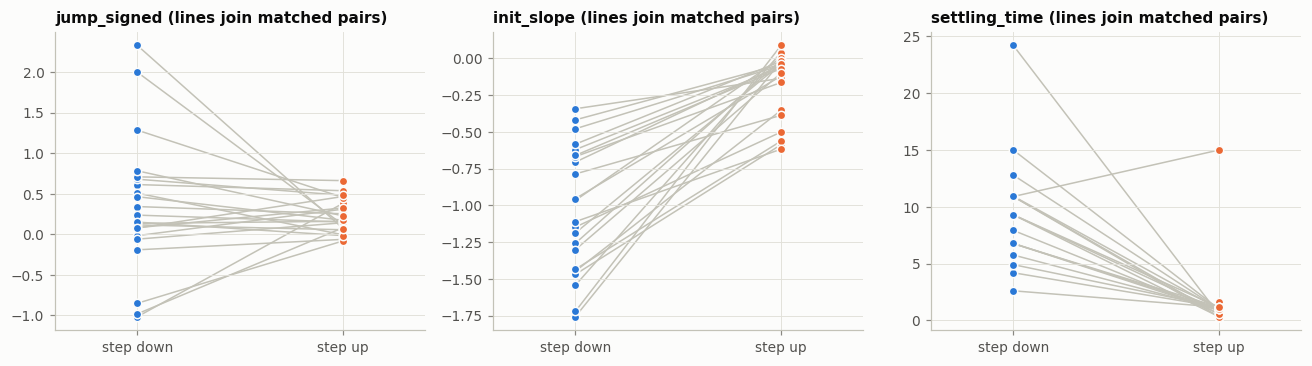

In [109]:
def rule_accuracy(df):
    ok = df.jump_signed.notna()
    return ((df.jump_signed[ok] > 0) == (df.direction[ok] == "up")).mean()

paired_ids = set(pairs.up_id) | set(pairs.down_id)
P = A[A.step_id.isin(paired_ids)]
rng = np.random.default_rng(0)
samples = P["sample"].unique()
boot = [rule_accuracy(pd.concat([P[P["sample"] == s] for s in rng.choice(samples, len(samples))])) for _ in range(2000)]
print(f"Direction rule 'jump_signed > 0 => up' on matched pairs: accuracy {rule_accuracy(P):.2f} "
      f"(95% workbook-bootstrap CI {np.percentile(boot, 2.5):.2f}-{np.percentile(boot, 97.5):.2f}, n = {len(P)} steps)")
print(f"Same rule on all steps (confounded by starting rate): {rule_accuracy(A):.2f}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, f in zip(ax, ["jump_signed", "init_slope", "settling_time"]):
    for _, r in pairs.iterrows():
        a.plot([0, 1], [r[f"down_{f}"], r[f"up_{f}"]], "-", color=AXIS, lw=1, zorder=1)
    a.scatter(np.zeros(len(pairs)), pairs[f"down_{f}"], s=30, color=DIR_COL["down"], edgecolor=SURFACE, zorder=2, label="step down")
    a.scatter(np.ones(len(pairs)), pairs[f"up_{f}"], s=30, color=DIR_COL["up"], edgecolor=SURFACE, zorder=2, label="step up")
    a.set_xlim(-0.4, 1.4)
    a.set_xticks([0, 1], ["step down", "step up"]); a.set_title(f"{f} (lines join matched pairs)")
fig.tight_layout(); fig.savefig(FIG / "06_direction_pairs.png", dpi=200); plt.show()

### 7.2b Evidence summary: magnitude and direction

**How to read this chart.** Left, *magnitude*: one cell per feature and direction. The colour is the median Spearman correlation between the feature and the step size within a family: red = the feature rises with step size, blue = it falls, grey = no relation. The text gives that median and how many blood samples had a positive correlation; * marks a consistent, significant pattern. Right, *direction*: for each feature, the share of the 22 matched pairs in which the step **up** has the larger value. Dots far from the 0.5 *chance* line in either direction mean the feature tells up from down; a filled dot means the pattern holds consistently across blood samples.

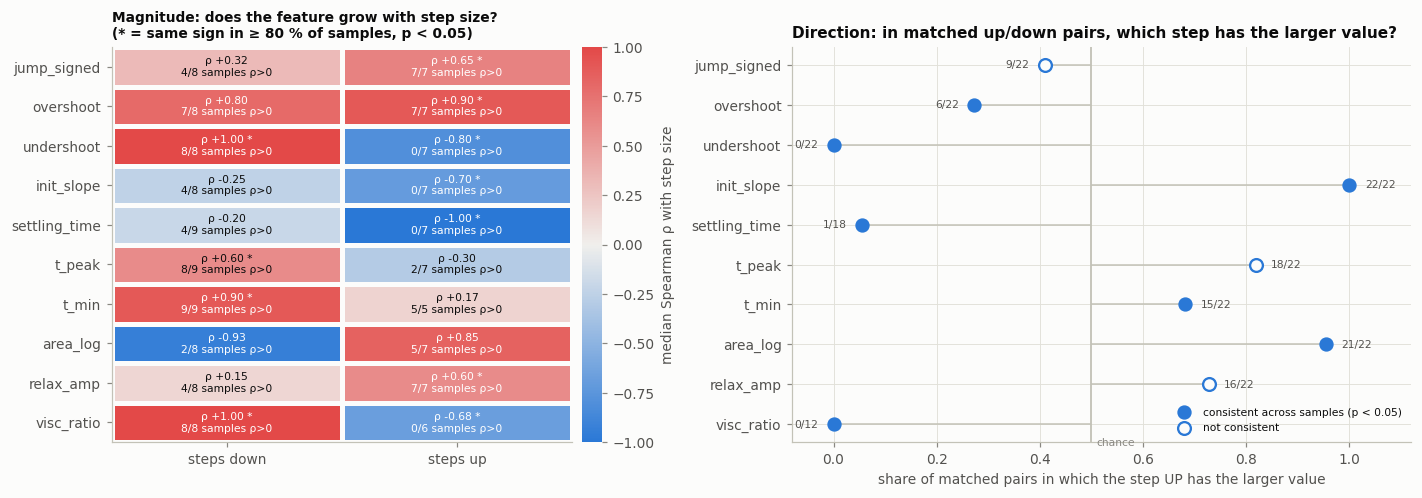

In [110]:
from matplotlib.colors import LinearSegmentedColormap
R_ = res_mag.assign(share=lambda q: q.workbooks_rho_pos / q.n_workbooks)
feat_order = FEATURES
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1, 1.25]))
Pm = R_.pivot(index="feature", columns="direction", values="median_rho").reindex(feat_order)[["down", "up"]]
im = ax[0].pcolormesh(Pm.values, cmap=LinearSegmentedColormap.from_list("div", DIVERGING), vmin=-1, vmax=1,
                      edgecolors=SURFACE, linewidth=2)
for i, f in enumerate(feat_order):
    for j, dirn in enumerate(["down", "up"]):
        r = R_[(R_.feature == f) & (R_.direction == dirn)]
        if len(r):
            r = r.iloc[0]
            txt = f"ρ {r.median_rho:+.2f}" + (" *" if r.sign_test_p < 0.05 else "") + f"\n{int(r.workbooks_rho_pos)}/{int(r.n_workbooks)} samples ρ>0"
            ax[0].text(j + 0.5, i + 0.5, txt, ha="center", va="center", fontsize=7,
                       color="white" if abs(r.median_rho) > 0.6 else INK)
ax[0].set_xticks([0.5, 1.5], ["steps down", "steps up"]); ax[0].set_yticks(np.arange(len(feat_order)) + 0.5, feat_order)
ax[0].invert_yaxis(); ax[0].grid(False)
cb = fig.colorbar(im, ax=ax[0], pad=0.02, fraction=0.05); cb.set_label("median Spearman ρ with step size", color=INK2); cb.outline.set_visible(False)
ax[0].set_title("Magnitude: does the feature grow with step size?\n(* = same sign in ≥ 80 % of samples, p < 0.05)", fontsize=9)

D_ = res_dir.set_index("feature").reindex(feat_order)
frac = D_.pairs_up_gt_down.str.split("/").apply(lambda z: int(z[0]) / int(z[1]))
sig = (D_.sign_test_p < 0.05)
y = np.arange(len(feat_order))
ax[1].axvline(0.5, color=AXIS, lw=1.2)
ax[1].text(0.51, len(feat_order) - 0.45, "chance", ha="left", fontsize=7, color=MUTED)
ax[1].hlines(y, 0.5, frac, color=AXIS, lw=1)
ax[1].scatter(frac[sig], y[sig.values], s=70, color=PAL[0], zorder=3, label="consistent across samples (p < 0.05)")
ax[1].scatter(frac[~sig], y[~sig.values], s=70, facecolor=SURFACE, edgecolor=PAL[0], lw=1.5, zorder=3, label="not consistent")
for yi, f_, lab in zip(y, frac, D_.pairs_up_gt_down):
    ax[1].text(f_ + (0.03 if f_ >= 0.5 else -0.03), yi, lab, va="center", ha="left" if f_ >= 0.5 else "right", fontsize=7, color=INK2)
ax[1].set_yticks(y, feat_order); ax[1].invert_yaxis(); ax[1].set_xlim(-0.08, 1.12)
ax[1].set(xlabel="share of matched pairs in which the step UP has the larger value",
          title="Direction: in matched up/down pairs, which step has the larger value?")
ax[1].legend(loc="lower right", fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "05b_evidence_summary.png", dpi=200); plt.show()

**What it shows.** *Magnitude* is encoded, but by different features in each direction. For step-downs, `undershoot`, `t_min` and `visc_ratio` rise with step size in every blood sample. For step-ups, `overshoot`, `jump_signed` and `relax_amp` rise with step size, while `init_slope`, `settling_time` and `undershoot` fall. *Direction*: `undershoot` (0 of 22 pairs larger for the step up), `init_slope` (22 of 22), `area_log` (21 of 22), `settling_time` and `visc_ratio` sit far from the chance line, while `jump_signed` (9 of 22) stays close to it.

**How to read this chart.** Each row is a rule for telling a step up from a step down. The dot is its accuracy on the matched pairs and the bar its 95 % confidence interval, obtained by resampling whole blood samples (so repeated steps from one sample are not counted as independent). The grey line at 50 % is what guessing would achieve. The hollow black dot is the rule fixed *before* the analysis; the blue dots are rules noticed *after* looking at the data, which need confirming on new samples.

,rule,accuracy,lo,hi
0,jump_signed > 0 ⇒ up (pre-specified),0.545,0.458,0.639
1,larger undershoot ⇒ the step down (exploratory),1.000,1.000,1.000
2,steeper initial fall ⇒ the step down (explorat...,1.000,1.000,1.000
3,larger area_log ⇒ the step up (exploratory),0.955,0.812,1.000


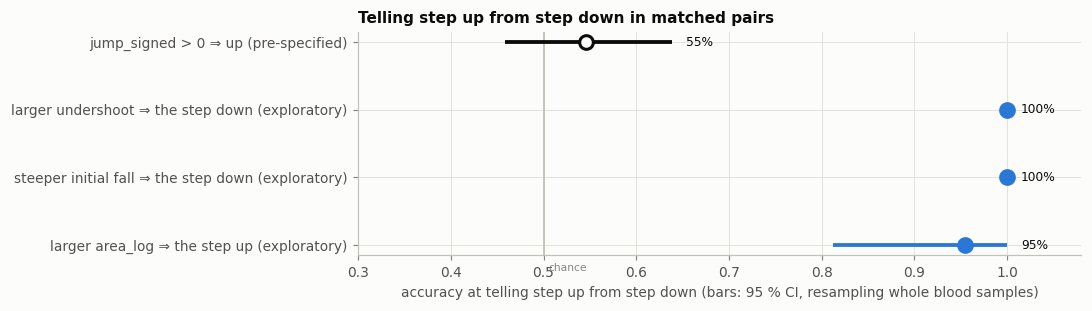

In [111]:
def pair_rule_acc(df, rule):
    return rule(df).mean()

rules = {
    "jump_signed > 0 ⇒ up (pre-specified)": None,
    "larger undershoot ⇒ the step down (exploratory)": lambda q: q.down_undershoot > q.up_undershoot,
    "steeper initial fall ⇒ the step down (exploratory)": lambda q: q.down_init_slope < q.up_init_slope,
    "larger area_log ⇒ the step up (exploratory)": lambda q: q.up_area_log > q.down_area_log,
}
rng_ = np.random.default_rng(0); smp = pairs["sample"].unique(); rows_ = []
for name, rule in rules.items():
    if rule is None:
        est = rule_accuracy(P)
        bs = [rule_accuracy(pd.concat([P[P["sample"] == s_] for s_ in rng_.choice(samples, len(samples))])) for _ in range(2000)]
    else:
        est = pair_rule_acc(pairs, rule)
        bs = [pair_rule_acc(pd.concat([pairs[pairs["sample"] == s_] for s_ in rng_.choice(smp, len(smp))]), rule) for _ in range(2000)]
    rows_.append(dict(rule=name, accuracy=est, lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5)))
acc = pd.DataFrame(rows_)
display(acc.round(3))
fig, ax = plt.subplots(figsize=(10, 2.9))
y = np.arange(len(acc))
ax.axvline(0.5, color=AXIS, lw=1.2); ax.text(0.505, len(acc) - 0.62, "chance", ha="left", fontsize=7, color=MUTED)
for yi, r in zip(y, acc.itertuples()):
    pre_ = "pre-specified" in r.rule
    c_ = INK if pre_ else PAL[0]
    ax.hlines(yi, r.lo, r.hi, color=c_, lw=2.5)
    ax.scatter(r.accuracy, yi, s=80, color=SURFACE if pre_ else c_, edgecolor=c_, lw=2, zorder=3)
    ax.text(min(r.hi, 1) + 0.015, yi, f"{r.accuracy:.0%}", va="center", fontsize=8)
ax.set_yticks(y, acc.rule); ax.invert_yaxis(); ax.set_xlim(0.3, 1.08)
ax.set(xlabel="accuracy at telling step up from step down (bars: 95 % CI, resampling whole blood samples)",
       title="Telling step up from step down in matched pairs")
fig.tight_layout(); fig.savefig(FIG / "06b_direction_rules.png", dpi=200); plt.show()

**What it shows.** The rule fixed before the analysis is no better than guessing: about 55 %, with a confidence interval that includes 50 %. Two rules found afterwards, "the step with the larger undershoot is the step down" and "the step with the steeper initial fall is the step down", are correct in every matched pair, and `area_log` in 21 of 22. Because these three rules were chosen *after* seeing the data, they are hypotheses to confirm on new blood samples, not validated classifiers.

**Result (direction).** The **pre-specified rule failed**: `jump_signed > 0 ⇒ up` is right for only 55 % of matched steps (95 % CI 46–64 %), no better than chance. The reason is visible in §6.4: straight after a step down, the stress is still relaxing elastically from its previous, higher level, so the first point is often *above* the new plateau. This negative result is kept.

Among the other features, three separate up from down in the matched pairs very consistently:
* **undershoot**: larger for the step down in **22/22 pairs** (10/10 workbooks)
* **init_slope**: steeper decline for the step down in **22/22 pairs**
* **area_log**: larger for the step up in **21/22 pairs**

These were identified **after** seeing the data, so they are exploratory and need confirmation on new samples before being used as a classifier. They also make physical sense: a step down produces an elastic dip followed by structural recovery (the undershoot), while a step up produces an overshoot that decays within about 1 s, as Pincot et al. (2023) describe.

### 7.3 Transient vs stable portions
For every measurement, three window-level descriptors are computed separately in W_T and W_S. They use only the window's own data and σ_stable as a scale:

* `abs_slope`: |d(σ/σ_stable)/d log₁₀ t| — how fast stress is still changing
* `abs_dev`: mean |σ − σ_stable|/σ_stable — distance from the steady value
* `cv`: coefficient of variation of σ within the window

The comparison is **paired within each measurement** (W_T vs W_S of the same step), then summarised per workbook and tested across workbooks.

In [112]:
def window_desc(d, t0, t1, ss):
    w = window(d, t0, t1)
    if len(w) < 3 or not np.isfinite(ss) or abs(ss) < NOISE_PA: return dict(abs_slope=np.nan, abs_dev=np.nan, cv=np.nan)
    x = np.log10(w.time.values); y = w.stress.values / ss
    return dict(abs_slope=abs(np.polyfit(x, y, 1)[0]), abs_dev=np.mean(np.abs(y - 1)), cv=np.std(y) / abs(np.mean(y)))

def phase_table(t_trans_end, t_stable_start):
    rows = []
    for _, r in A.iterrows():
        b = next(bb for bb in blocks if bb["step_id"] == r.step_id)
        ws = window(b["an"], t_stable_start, np.inf); ss = np.median(ws.stress) if len(ws) else np.nan
        rows.append(dict(step_id=r.step_id, sample=r["sample"], stable_ok=r.stable_ok,
                         **{f"T_{k}": v for k, v in window_desc(b["an"], r.t_rate_settle, t_trans_end, ss).items()},
                         **{f"S_{k}": v for k, v in window_desc(b["an"], t_stable_start, np.inf, ss).items()}))
    return pd.DataFrame(rows)

def phase_result(ph, label):
    out = []
    for k in ["abs_slope", "abs_dev", "cv"]:
        diff = np.log10(ph[f"T_{k}"].clip(lower=1e-6) / ph[f"S_{k}"].clip(lower=1e-6))   # log ratio transient/stable
        wbm = diff.groupby(ph["sample"]).median()
        p, kk, n = sign_test(wbm)
        out.append(dict(rule=label, descriptor=k, measurements_T_gt_S=f"{(diff > 0).sum()}/{diff.notna().sum()}",
                        median_log10_ratio_T_over_S=diff.median(), workbooks_T_gt_S=f"{kk}/{n}", sign_test_p=p))
    return out

ph = phase_table(TRANSIENT_END, STABLE_START)
res_phase = pd.DataFrame(phase_result(ph, "primary (2 s / 30 s)"))
res_phase.round(4)

,rule,descriptor,measurements_T_gt_S,median_log10_ratio_T_over_S,workbooks_T_gt_S,sign_test_p
0,primary (2 s / 30 s),abs_slope,106/128,0.5381,11/11,0.001
1,primary (2 s / 30 s),abs_dev,127/128,1.3827,11/11,0.001
2,primary (2 s / 30 s),cv,127/128,1.2814,11/11,0.001


### 7.4 Sensitivity to the transient/stable boundaries
The framework asks for the boundary choice to be checked. The same test is repeated with shorter and longer windows. A conclusion that holds under all three is robust; one that flips is reported as boundary-dependent.

**How to read the box chart (after the table).** For each descriptor, the orange box summarises its value in the transient window and the green box in the stable window, across all measurements; the thin grey lines join the two windows of the same measurement. The vertical axis is logarithmic. Values that are consistently higher on the left mean the descriptor tells the phases apart.

In [113]:
sens = pd.concat([pd.DataFrame(phase_result(phase_table(a, b), name)) for name, (a, b) in RULE_VARIANTS.items()])
sens.to_csv(OUT / "result_transient_vs_stable.csv", index=False)
sens.pivot(index="descriptor", columns="rule", values="workbooks_T_gt_S")

rule,long (5 s / 40 s),primary (2 s / 30 s),short (1 s / 20 s)
descriptor,,,
abs_dev,11/11,11/11,11/11
abs_slope,9/11,11/11,11/11
cv,11/11,11/11,11/11


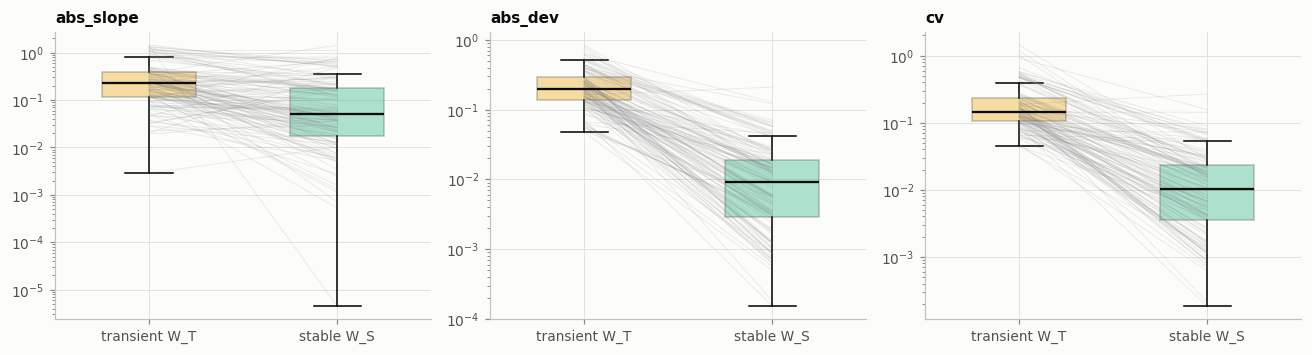

In [114]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for a, k in zip(ax, ["abs_slope", "abs_dev", "cv"]):
    bp = a.boxplot([ph[f"T_{k}"].dropna(), ph[f"S_{k}"].dropna()], tick_labels=["transient W_T", "stable W_S"],
                   showfliers=False, patch_artist=True, medianprops=dict(color=INK, lw=1.5), widths=0.5)
    for patch, c in zip(bp["boxes"], [WIN_T, WIN_S]): patch.set(facecolor=c, alpha=0.35, edgecolor=INK2)
    for _, r in ph.iterrows():
        a.plot([1, 2], [r[f"T_{k}"], r[f"S_{k}"]], color="grey", alpha=0.15, lw=0.6)
    a.set_yscale("log"); a.set_title(k)
fig.tight_layout(); fig.savefig(FIG / "07_transient_vs_stable.png", dpi=200); plt.show()

**How to read this chart.** Each line is one of the three window descriptors. The vertical axis is the share of blood samples in which the descriptor is larger in the transient window than in the stable window (1.0 = every sample; 0.5 = chance). The horizontal axis is the choice of window boundaries. Flat lines near 1.0 mean the conclusion does not depend on exactly where the windows are drawn; a count is shown wherever a descriptor falls short of every sample.

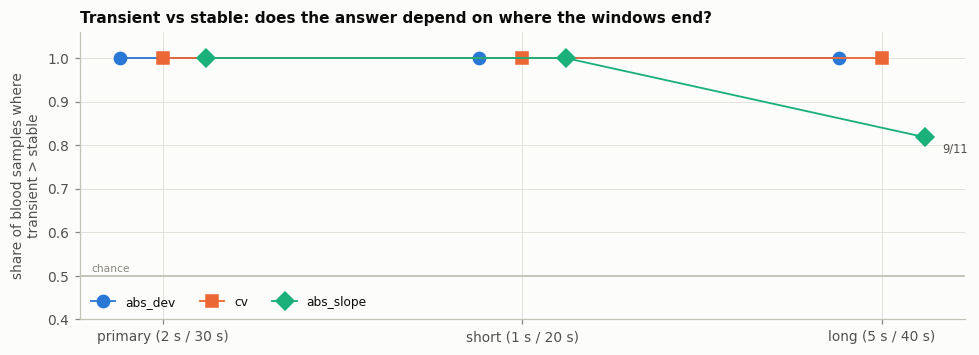

In [115]:
Sv = sens.assign(share=sens.workbooks_T_gt_S.str.split("/").apply(lambda z: int(z[0]) / int(z[1])))
order_r = list(RULE_VARIANTS)
fig, ax = plt.subplots(figsize=(9, 3.3))
for i, k in enumerate(["abs_dev", "cv", "abs_slope"]):
    q = Sv[Sv.descriptor == k].set_index("rule").reindex(order_r)
    x = np.arange(len(order_r)) + (i - 1) * 0.12
    ax.plot(x, q.share, marker="osD"[i], ms=8, lw=1.2, color=PAL[i], label=k)
    for xi, s_, lab in zip(x, q.share, q.workbooks_T_gt_S):
        if s_ < 1: ax.text(xi + 0.05, s_ - 0.035, lab, fontsize=7.5, color=INK2)
ax.axhline(0.5, color=AXIS, lw=1.2); ax.text(-0.2, 0.51, "chance", fontsize=7, color=MUTED)
ax.set_xticks(range(len(order_r)), order_r); ax.set_ylim(0.4, 1.06)
ax.set(ylabel="share of blood samples where\ntransient > stable", title="Transient vs stable: does the answer depend on where the windows end?")
ax.legend(loc="lower left", ncol=3)
fig.tight_layout(); fig.savefig(FIG / "07b_boundary_sensitivity.png", dpi=200); plt.show()

**What it shows.** `abs_dev` and `cv` are larger in the transient window than in the stable window in every blood sample, whichever boundaries are used. `abs_slope` behaves the same with the primary and short boundaries but falls to about 83 % of samples with the long rule (transient window ending at 5 s), because most responses have already flattened by then. The transient/stable distinction is therefore robust, and `abs_dev` or `cv` are the descriptors to use.

**Result (transient vs stable).** All three descriptors are higher in the transient window than in the stable window **in 11/11 workbooks** (127/128 measurements for `abs_dev` and `cv`). The conclusion holds under all three boundary choices. The one exception is `abs_slope` with the long rule (5 s / 40 s), which drops to 9/11 because by 5 s most responses have already levelled off. **`abs_dev` and `cv` are the robust choice; `abs_slope` depends on where the transient window ends.**

### 7.5 Storage time (DEC17 at 0, 12 and 24 h)
Not one of the four framework questions, but DEC17 is the only workbook where the **same blood** was stepped at three storage times, which makes it the clearest demonstration of change. These are repeated measurements of one sample, so this is descriptive only.

**How to read this chart.** The horizontal axis is how long the DEC17 blood had been stored (0, 12, 24 h). Each line is one step condition (solid = step down, dotted = step up; marker shapes differ too). Left: the steady stress reached after the step (log scale). Middle: the signed jump. Right: the model's effective relaxation time after the step.

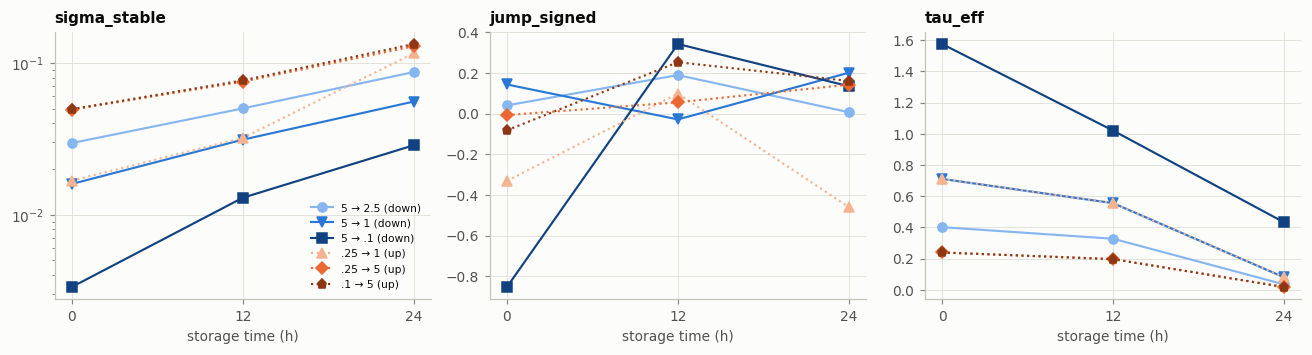

,storage_h,tau_lambda,G,sigma_y0,eta_ST,eta_inf,tr1,tr2
10,0.0,2.1677,0.2135,0.0011,0.0217,0.0027,1.2592,0.792
11,12.0,1.1897,0.2974,0.0000,0.0355,0.0038,0.9027,0.240
12,24.0,1.0508,0.4698,0.0000,0.3500,0.0052,11.2115,0.984


In [116]:
dec = A[A["sample"] == "DEC17"]
if len(dec):
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
    for a, f in zip(ax, ["sigma_stable", "jump_signed", "tau_eff"]):
        keep = ["5-->2.5", "5-->1", "5-->.1", ".25-->1", ".25-->5", ".1-->5"]
        for i, key in enumerate(keep):
            g = dec[dec.label.str.split("(").str[0].str.strip() == key].sort_values("storage_h")
            if g.storage_h.nunique() == 3:
                dirn = "down" if key.startswith("5") else "up"
                a.plot(g.storage_h, g[f], marker="ovs^Dp"[i], ms=6, ls="-" if dirn == "down" else ":", lw=1.4,
                       color=shades(dirn, 3)[i % 3], label=key.replace("-->", " → ") + f" ({dirn})")
        a.set(xlabel="storage time (h)", title=f, xticks=[0, 12, 24])
        if f == "sigma_stable": a.set_yscale("log")
    ax[0].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(FIG / "08_dec17_storage.png", dpi=200); plt.show()
    display(models[models["sample"] == "DEC17"][["storage_h", "tau_lambda", "G", "sigma_y0", "eta_ST", "eta_inf", "tr1", "tr2"]].round(4))

**How to read this chart.** The three fitted model parameters for the DEC17 blood at 0, 12 and 24 h of storage. Left: the structural time τ_λ with its uncertainty bars, against the green literature band (log scale). Middle: the elastic modulus G, with the published value as a black line. Right: the structural viscosity η_ST (log scale). One sample measured three times, so these trends are descriptive.

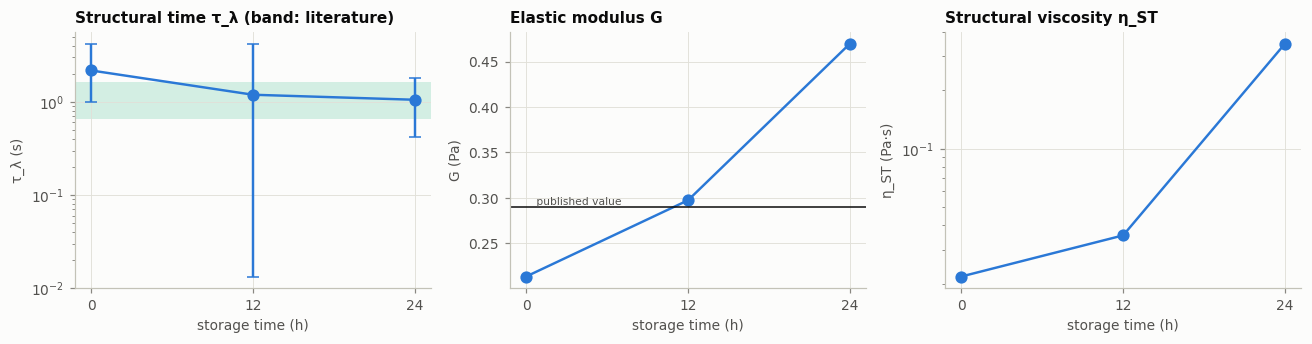

In [117]:
Dm = models[models["sample"] == "DEC17"].sort_values("storage_h")
if len(Dm) == 3:
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
    ax[0].errorbar(Dm.storage_h, Dm.tau_lambda, yerr=[Dm.tau_lambda - Dm.tau_lambda_lo, Dm.tau_lambda_hi - Dm.tau_lambda],
                   fmt="o-", ms=7, capsize=4, color=PAL[0])
    ax[0].axhspan(TAU_LAMBDA_LIT[0] - 2 * TAU_LAMBDA_LIT[1], TAU_LAMBDA_LIT[0] + 2 * TAU_LAMBDA_LIT[1], color=WIN_S, alpha=0.18, lw=0)
    ax[0].set(yscale="log", ylabel="τ_λ (s)", title="Structural time τ_λ (band: literature)")
    ax[1].plot(Dm.storage_h, Dm.G, "o-", ms=7, color=PAL[0]); ax[1].axhline(G_LIT_V1, color=INK, lw=1)
    ax[1].text(0.5, G_LIT_V1, " published value", va="bottom", fontsize=7, color=INK2)
    ax[1].set(ylabel="G (Pa)", title="Elastic modulus G")
    ax[2].plot(Dm.storage_h, Dm.eta_ST, "o-", ms=7, color=PAL[0]); ax[2].set(yscale="log", ylabel="η_ST (Pa·s)", title="Structural viscosity η_ST")
    for a in ax: a.set(xlabel="storage time (h)", xticks=[0, 12, 24])
    fig.tight_layout(); fig.savefig(FIG / "08b_dec17_model_parameters.png", dpi=200); plt.show()

**What it shows.** Over 24 h of storage the model's elastic modulus G rises steadily (about 0.22 → 0.30 → 0.47 Pa) and the structural viscosity η_ST rises more than tenfold, while τ_λ stays inside or near the literature band at all three times (with a very wide uncertainty interval at 12 h). Storage therefore changes how *stiff and viscous* the structure becomes much more clearly than how *fast* it rebuilds. This is one blood sample measured three times, so it is descriptive only.

**Result (DEC17 storage).** In the same blood over 24 h: σ_stable rises with storage time for all six step conditions shown, and the effective relaxation time τ_eff falls; the model gives **G 0.22 → 0.30 → 0.46 Pa** and **η_ST 0.021 → 0.036 → 0.34 Pa·s** (about 16× by 24 h), while τ_λ falls from 2.0 to about 1.1 s. This is consistent with increasing aggregation and stiffening of stored blood. It is one sample measured three times, so it is descriptive only.

## 8. Which transient metrics are reliable, inconclusive or unusable?

Each feature is classified with explicit, pre-stated criteria:

* **Computable fraction**: share of analysable measurements where the feature is finite.
* **Stable-state dependence**: features divided by σ_stable are downgraded when many measurements lack a defensible stable state.
* **Per question** (magnitude of step-downs, magnitude of step-ups, direction): `yes` if the effect has the same sign in ≥ 80 % of workbooks **and** the sign test gives p < 0.05, otherwise `no`.

| Class | Rule |
|---|---|
| reliable | computable in ≥ 80 % of measurements **and** `yes` for at least one question |
| inconclusive | computable in ≥ 50 % but no consistent effect |
| unusable | computable in < 50 % of measurements, or fitting fails in most cases |

With about 10 workbooks, even “reliable” means *consistent in this exploratory dataset*, not confirmed.

In [118]:
def verdict(p, share):
    """'yes' = consistent in >= 80 % of workbooks AND sign-test p < 0.05; otherwise 'no'."""
    if not np.isfinite(p): return "n/a"
    return "yes" if p < 0.05 and max(share, 1 - share) >= 0.8 else "no"

rel = []
for f in FEATURES:
    row = dict(feature=f, computable=round(A[f].notna().mean(), 2))
    for dirn in ("down", "up"):
        m = res_mag[(res_mag.feature == f) & (res_mag.direction == dirn)]
        row[f"magnitude_{dirn}"] = (verdict(m.sign_test_p.iloc[0], m.workbooks_rho_pos.iloc[0] / max(m.n_workbooks.iloc[0], 1))
                                    if len(m) else "n/a")
    d = res_dir[res_dir.feature == f]
    row["direction"] = verdict(d.sign_test_p.iloc[0], d.workbooks_up_gt_down.iloc[0] / max(d.n_workbooks.iloc[0], 1)) if len(d) else "n/a"
    n_yes = sum(row[k] == "yes" for k in ("magnitude_down", "magnitude_up", "direction"))
    row["needs_stable_state"] = f in ("jump_signed", "overshoot", "undershoot", "init_slope", "area_log", "settling_time")
    row["classification"] = "unusable" if row["computable"] < 0.5 else "reliable" if row["computable"] >= 0.8 and n_yes else "inconclusive"
    rel.append(row)
fit_share = (fits_exp.status == "ok").mean()
rel.append(dict(feature="tau (single exponential)", computable=round(fit_share, 2),
                classification="unusable" if fit_share < 0.5 else "inconclusive"))
rel.append(dict(feature="tau_lambda, G (ethixo-EVP, per workbook)", computable=round((~models.k_at_bound).mean(), 2),
                classification="reliable" if (~models.k_at_bound).mean() >= 0.8 else "inconclusive"))
rel = pd.DataFrame(rel)
rel.to_csv(OUT / "metric_reliability.csv", index=False)
rel

,feature,computable,magnitude_down,magnitude_up,direction,needs_stable_state,classification
0,jump_signed,0.96,no,yes,no,True,reliable
1,overshoot,0.96,no,yes,yes,True,reliable
2,undershoot,0.96,yes,yes,yes,True,reliable
3,init_slope,0.96,no,yes,yes,True,reliable
4,settling_time,0.92,no,yes,yes,True,reliable
5,t_peak,1.00,yes,no,no,False,reliable
6,t_min,1.00,yes,no,yes,False,reliable
7,area_log,0.96,no,no,yes,True,reliable
8,relax_amp,0.96,no,yes,no,False,reliable
9,visc_ratio,0.83,yes,yes,yes,False,reliable


**How to read this chart.** One row per metric. *Computable* shows the share of step tests where the metric could be calculated (the blue bar fills the cell at 100 %). The three middle columns show whether the metric answers each question: ✓ yes (the same pattern in ≥ 80 % of blood samples, p < 0.05) or no. The last column is the overall classification from the rules above.

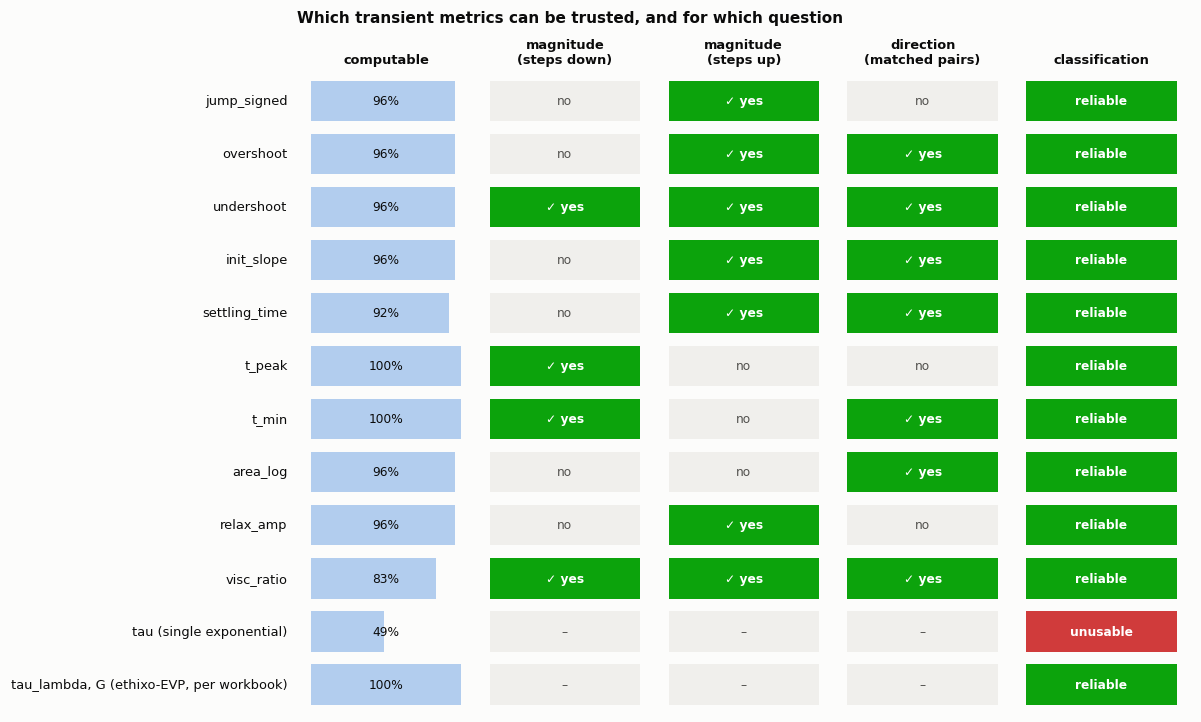

In [119]:
cols_q = ["magnitude_down", "magnitude_up", "direction"]
Rl = rel.set_index("feature")
fig, ax = plt.subplots(figsize=(11, 0.42 * len(Rl) + 1.6))
ax.set_xlim(0, 5); ax.set_ylim(len(Rl), 0); ax.axis("off")
heads = ["computable", "magnitude\n(steps down)", "magnitude\n(steps up)", "direction\n(matched pairs)", "classification"]
for j, h in enumerate(heads):
    ax.text(j + 0.5, -0.15, h, ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=INK)
cls_col = {"reliable": STATUS["good"], "inconclusive": STATUS["warning"], "unusable": STATUS["critical"]}
for i, (f, r) in enumerate(Rl.iterrows()):
    ax.text(-0.05, i + 0.5, f, ha="right", va="center", fontsize=8.5)
    ax.add_patch(plt.Rectangle((0.08, i + 0.12), 0.84 * (r.computable if np.isfinite(r.computable) else 0), 0.76, color=PAL[0], alpha=0.35, lw=0))
    ax.text(0.5, i + 0.5, f"{r.computable:.0%}" if np.isfinite(r.computable) else "", ha="center", va="center", fontsize=8)
    for j, c in enumerate(cols_q, start=1):
        v = r.get(c, np.nan)
        v = v if isinstance(v, str) else "–"
        fc = STATUS["good"] if v == "yes" else NEUTRAL
        ax.add_patch(plt.Rectangle((j + 0.08, i + 0.12), 0.84, 0.76, color=fc, lw=0))
        ax.text(j + 0.5, i + 0.5, ("✓ " if v == "yes" else "") + v, ha="center", va="center", fontsize=8,
                color="white" if v == "yes" else INK2, fontweight="bold" if v == "yes" else "normal")
    ax.add_patch(plt.Rectangle((4.08, i + 0.12), 0.84, 0.76, color=cls_col.get(r.classification, NEUTRAL), lw=0))
    ax.text(4.5, i + 0.5, r.classification, ha="center", va="center", fontsize=8,
            color="white" if r.classification != "inconclusive" else INK, fontweight="bold")
ax.set_title("Which transient metrics can be trusted, and for which question", pad=34)
fig.tight_layout(); fig.savefig(FIG / "09_metric_reliability.png", dpi=200); plt.show()

**What it shows.** All ten conventional features can be computed for at least 81 % of steps, and each answers at least one question, so all are classed *reliable* under the stated rule, but for different questions. `undershoot` and `visc_ratio` answer all three; `init_slope`, `settling_time` and `overshoot` answer step-up magnitude and direction; `t_peak` and `t_min` mainly step-down magnitude (`t_min` also direction); `area_log` only direction; `jump_signed` and `relax_amp` only step-up magnitude. The single-exponential τ sits on the 50 % computability boundary, so one step decides whether it is *inconclusive* or *unusable*. τ_λ and G are reliable only as one value per blood sample. `visc_ratio` partly restates the step itself (viscosity rises when the rate falls), so it is a weak candidate for the minimal feature set.

## 9. Summary for the report and hand-over to Members 4 and 5

In [120]:
print("=== Data and verification ===")
print(f"step blocks analysed: {len(A)} from {A['sample'].nunique()} workbooks; label mismatches excluded: {(steps.qc_rate == 'MISMATCH with label').sum()}")
print(f"instrument window (rate settling): median {ev.t_rate_settle.median():.3f} s, max {ev.t_rate_settle.max():.3f} s")
print(f"defensible stable state within 63 s: {A.stable_ok.mean():.0%} of steps")
print("\n=== Relaxation model ===")
print(f"single exponential interpretable: {(fits_exp.status == 'ok').mean():.0%} of steps")
okm = models[~models.k_at_bound]
print(f"ethixo-EVP tau_lambda: median {okm.tau_lambda.median():.2f} s over {len(okm)} identifiable fits "
      f"(literature 1.13 +- 0.24 s); steps with acceptable fit (NRMSE <= {MODEL_MAX_NRMSE}): "
      f"{(A.nrmse_model <= A.fit_threshold).mean():.0%}")
print("\n=== Questions ===")
print("Magnitude (strongest):"); print(res_mag.nsmallest(3, "sign_test_p")[["feature", "direction", "median_rho", "workbooks_rho_pos", "n_workbooks", "sign_test_p"]].round(3).to_string(index=False))
print("Direction (matched pairs):"); print(res_dir.head(3)[["feature", "median_up_minus_down", "workbooks_up_gt_down", "n_workbooks", "sign_test_p"]].round(4).to_string(index=False))
print("Transient vs stable (all rule variants):"); print(sens[["rule", "descriptor", "workbooks_T_gt_S", "sign_test_p"]].round(4).to_string(index=False))
print(f"\nAll tables written to {OUT.resolve()}")

=== Data and verification ===
step blocks analysed: 133 from 11 workbooks; label mismatches excluded: 3
instrument window (rate settling): median 0.050 s, max 0.108 s
defensible stable state within 63 s: 86% of steps

=== Relaxation model ===
single exponential interpretable: 49% of steps
ethixo-EVP tau_lambda: median 0.65 s over 13 identifiable fits (literature 1.13 +- 0.24 s); steps with acceptable fit (NRMSE <= 0.1): 38%

=== Questions ===
Magnitude (strongest):
   feature direction  median_rho  workbooks_rho_pos  n_workbooks  sign_test_p
     t_min      down         0.9                  9            9        0.004
undershoot      down         1.0                  8            8        0.008
visc_ratio      down         1.0                  8            8        0.008
Direction (matched pairs):
   feature  median_up_minus_down  workbooks_up_gt_down  n_workbooks  sign_test_p
undershoot               -0.4882                     0           10       0.0020
init_slope                0.8



### Limitations
Around 10 independent blood samples; results are exploratory. The model is the scalar (non-tensorial) ethixo-EVP version 1 with n = 1; the papers' later tensorial models (t-e-TVP, t-ESSTV) were not implemented. k_λ's interval is a conditional profile (other parameters held fixed), so it understates the true uncertainty. The pre-step state is assumed to be steady at the initial rate. Changes in stress are *consistent with* rouleaux breakdown and aggregation but do not prove a mechanism.

## References

### Papers supplied by the team (used directly in this notebook)

1. **Armstrong, M., Scully, M., Clark, M., Corrigan, T. & James, C. (2021).** A simple approach for adding thixotropy to an elasto-visco-plastic rheological model to facilitate structural interrogation of human blood. *Journal of Non-Newtonian Fluid Mechanics*, 290, 104503.
   *Used for:* the ethixo-EVP model (Eqs. 10, 11, 13, 16) fitted in §6; the relative steady-state cost (Eq. 17) and the step-up/down transient cost (Eq. 18); the published G = 0.29 Pa used as a validation target; the step protocols (5 → 0.1/1/2.5 s⁻¹ and 0.25 → 1/2.5/5 s⁻¹).
2. **Armstrong, M., Pincot, A., Rogers, S., Knight, T. & Bailey, D. (2022).** Recent advances in biofluid mechanics and bio- and hemorheology: collating recent advances in predicting complex behavior of human blood with thixo-elasto-visco-plastic models and sequence of physical process. *Frontiers in Physics*, 10, 889065.
   *Used for:* simultaneous fitting of steady-state and step data with each step normalised by its maximum stress (Eq. 12); the 12-donor literature values τ_λ = 1.13 ± 0.24 s and G_R = 0.15 ± 0.05 Pa (§6.3); the finding that breakdown is faster than aggregation.
3. **Pincot, A. & Armstrong, M. (2021).** Novel tensorial thixo-visco-plastic framework for rheological characterization of human blood. *Scientific Reports*, 11, 22004.
   *Used for:* the experimental protocol (ARES-G2, double-wall Couette, 37 °C, pre-shear 300 s⁻¹ for 30 s); the fixed exponent d = ½; τ_λ = 0.55–0.96 s for Donor 1; AIC/BIC reporting.
4. **Pincot, A., Burpo, F. J., Javadi, E., Jamali, S., Farrington, S. & Armstrong, M. J. (2023).** Characterizing blood hysteresis via tensorial thixo-elasto-viscoplastic modeling. *Physics of Fluids*, 35, 113104.
   *Used for:* the physical interpretation of overshoot on step-up and undershoot-then-recovery on step-down (rouleaux breakdown faster than aggregation); step-up overshoots decaying within about 1 s.

### Datasets (the client workbooks; published by the same group on Mendeley Data)

5. Armstrong, M. & Horner, J. (2020). *Rheology data of human blood JUN18; SAOS, step up/down, LAOS, UDLAOS, cessation of flow with ARESG2.* Mendeley Data, v1. https://doi.org/10.17632/948ffnypjs.1
6. Armstrong, M. & Horner, J. (2020). *Rheology data of human blood JUL18; SAOS, step up/down, LAOS, UDLAOS with ARESG2.* Mendeley Data, v1. https://doi.org/10.17632/s8w6s6f68b
7. Armstrong, M. (2020). *DEC17 ARESG2 human blood rheology: SS, SAOS, LAOS, steps, etc.* Mendeley Data. https://doi.org/10.17632/d43r5ydpx8.1
8. Armstrong, M. & Horner, J. (2020). *FEB18 blood rheology ARESG2 SS SAOS LAOS step.* Mendeley Data, v1. https://doi.org/10.17632/jdzpx6hy6r.1
9. Armstrong, M. J. & Horner, J. (2022). *APR18 SS SAOS LAOS & UDLAOS of human blood.* Mendeley Data, v1. https://doi.org/10.17632/6jjryg2f8v.1
10. Armstrong, M. J. & Horner, J. (2022). *MAR19 SS, steps, SAOS, LAOS, UDLAOS human blood.* Mendeley Data, v1. https://doi.org/10.17632/6dx72mxmy9.1
11. Armstrong, M. J. & Horner, J. (2022). *MAY19 UDEL blood.* Mendeley Data, v1. https://doi.org/10.17632/k8fxtjhcxj.1

The remaining workbooks (12FEB20, 27FEB19, NOV18, 14DEC, AUG18) were supplied by the client; no published DOI for them was found in the four papers.

### Additional sources (cited in the text, not supplied by the team)

12. **Wei, Y., Solomon, M. J. & Larson, R. G. (2018).** Quantitative nonlinear thixotropic model with stretched exponential response in transient shear flows. *Journal of Rheology*, 62, 321–342. *Cited in §6 as the multi-time-scale thixotropy explanation for the slow recovery a single-λ model cannot fit (referenced by Armstrong et al. 2021).*
13. **Bureau, M., Healy, J., Bourgoin, D. & Joly, M. (1980).** Rheological hysteresis of blood at low shear rate. *Biorheology*, 17, 191–203. *Origin of the "Bureau" start-up-and-stop tests in FEB18, which are excluded as out of scope (referenced by Armstrong et al. 2021).*
14. **Das, M., Hudson-Kershaw, R. E., Yang, Y., Curtis, D. J. & McKinley, G. H. (2024).** The effect of instrument inertia on the initiation of oscillatory flow in stress-controlled rheometry. *Journal of Rheology*, 68, 365–383. *Cited in §2 for excluding the motor-inertia window after each step (referenced in the Group 24 Semester 1 report).*
15. **Virtanen, P. et al. (2020).** SciPy 1.0: fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261–272. *Software: ODE integration (LSODA via `solve_ivp`), least-squares fitting and statistical tests.*

### Project documents

16. Group 24 (2026). *Work Allocation Framework for LAOS and Step Rheology Analysis* (five-member project plan; Member 3 tasks followed in this notebook).
17. Group 24 (2026). *Wavelet-Based Time-Frequency Analysis for Gel-Point Detection in Non-Stationary Rheological Signals from a Microfluidic Rheometer.* Semester 1 report, Master of Data Science, University of Melbourne.
18. Group 24, Member 1 (2026). *Part 1: LAOS and Step-Up/Down Data Processing* (`data_processing_pipeline.py`, `measurement_index.csv`, `standardized_signals.csv.gz`).